In [ ]:
import polars as pl
import folium

import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import umap
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min


import networkx as nx
import seaborn as sns
import pyarrow

from scipy.optimize import minimize
from scipy.special import gammaln
from sklearn.cluster import SpectralClustering

#in case graph tool is installed
#import graph_tool.all as gt

c:\Users\eliav\OneDrive\Documents\Julian\github\Dauphine\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Read df to use
df = pl.read_parquet("../data/output/v2/2.clean_df_v2.parquet")

In [3]:
#-------------------------------
#le nombre total de trajets en 2025 ;
#--------------------------------

print(df.select(pl.count("Total duration (ms)")))

#After cleaning the data, there were 8'762,355 trips made in 2025


shape: (1, 1)
┌─────────────────────┐
│ Total duration (ms) │
│ ---                 │
│ u32                 │
╞═════════════════════╡
│ 8762355             │
└─────────────────────┘


In [4]:
#-------------------------------
# le nombre ou le ratio de stations actives ;
#-------------------------------

#number of active start stations 
print(df.select(pl.col("Start station number").unique_counts()))

#820 start stations where used in 2025

#number of active end stations
print(df.select(pl.col("End station number").unique_counts()))

#822 end stations where used in 2025

#Note, this could change if the 2 stations that only appear in the end station number column are removed in the cleaning step.(station ids 10626 and 22168)




shape: (820, 1)
┌──────────────────────┐
│ Start station number │
│ ---                  │
│ u32                  │
╞══════════════════════╡
│ 15056                │
│ 13531                │
│ 11088                │
│ 13191                │
│ 15764                │
│ …                    │
│ 237                  │
│ 3331                 │
│ 3125                 │
│ 841                  │
│ 37                   │
└──────────────────────┘
shape: (822, 1)
┌────────────────────┐
│ End station number │
│ ---                │
│ u32                │
╞════════════════════╡
│ 10167              │
│ 7337               │
│ 11464              │
│ 22345              │
│ 10075              │
│ …                  │
│ 4396               │
│ 3257               │
│ 3180               │
│ 831                │
│ 27                 │
└────────────────────┘


In [ ]:
# -------------------------------
# le nombre ou le ratio de stations utilisées comme stations de départ ;
#-------------------------------

#-------------------------------
# le nombre ou le ratio de stations utilisées comme stations d'arrivée ;
#-------------------------------


#Rate of active stations
start_ids = df["Start station number"].unique()
end_ids = df["End station number"].unique()

all_stations = pl.concat([start_ids, end_ids]).unique()

start_rate = start_ids.len() / all_stations.len()
end_rate = end_ids.len() / all_stations.len()

print(f"Start station active rate: {start_rate:.2%}")
print(f"End station active rate:   {end_rate:.2%}")

#almost 100% on both. which is normal actually since the empty stations where already filtered out



Start station active rate: 99.76%
End station active rate:   100.00%


In [6]:
#Most used start and end station
print(df.group_by("Start station number").len().sort("len", descending=True))

print(df.group_by("End station number").len().sort("len", descending=True))


shape: (820, 2)
┌──────────────────────┬───────┐
│ Start station number ┆ len   │
│ ---                  ┆ ---   │
│ i64                  ┆ u32   │
╞══════════════════════╪═══════╡
│ 1072                 ┆ 53880 │
│ 2696                 ┆ 46257 │
│ 1075                 ┆ 42737 │
│ 2587                 ┆ 39851 │
│ 1011                 ┆ 38519 │
│ …                    ┆ …     │
│ 200083444            ┆ 488   │
│ 11274444             ┆ 322   │
│ 1219444              ┆ 250   │
│ 200191444            ┆ 237   │
│ 2635                 ┆ 37    │
└──────────────────────┴───────┘
shape: (822, 2)
┌────────────────────┬───────┐
│ End station number ┆ len   │
│ ---                ┆ ---   │
│ i64                ┆ u32   │
╞════════════════════╪═══════╡
│ 1072               ┆ 50563 │
│ 2696               ┆ 44261 │
│ 960                ┆ 44106 │
│ 1161               ┆ 41383 │
│ 1067               ┆ 40483 │
│ …                  ┆ …     │
│ 11274444           ┆ 274   │
│ 1219444            ┆ 242   │
│ 20

In [8]:
#-------------------------------
# la distribution du nombre de trajets par jour ;
#-------------------------------

#Change date format to date time
#df = df.with_columns(
#    pl.col("Start date").str.to_datetime("%Y-%m-%d %H:%M"),
#    pl.col("End date").str.to_datetime("%Y-%m-%d %H:%M")
#)
#print(df)


print(df.group_by("Operating date").len().sort("len", descending=True))

#there is a huge gap between the 2 lowest dates: 2025-08-05 with 171 trajets and 2025-01-01 with 5077 trajets (could it be that the missing values removed in the cleaning belonged mostly to 2025-08-05 ?)


shape: (365, 2)
┌────────────────┬───────┐
│ Operating date ┆ len   │
│ ---            ┆ ---   │
│ date           ┆ u32   │
╞════════════════╪═══════╡
│ 2025-09-09     ┆ 44732 │
│ 2025-09-11     ┆ 41080 │
│ 2025-09-08     ┆ 40110 │
│ 2025-09-10     ┆ 36695 │
│ 2025-07-10     ┆ 34028 │
│ …              ┆ …     │
│ 2025-12-24     ┆ 8216  │
│ 2025-12-26     ┆ 6171  │
│ 2025-01-05     ┆ 5739  │
│ 2025-01-01     ┆ 5077  │
│ 2025-08-05     ┆ 171   │
└────────────────┴───────┘


In [9]:
#-------------------------------
# la distribution du nombre de trajets par station ;
#-------------------------------

#Most used start and end station
print(df.group_by("Start station number").len().sort("len", descending=True))

print(df.group_by("End station number").len().sort("len", descending=True))


shape: (820, 2)
┌──────────────────────┬───────┐
│ Start station number ┆ len   │
│ ---                  ┆ ---   │
│ i64                  ┆ u32   │
╞══════════════════════╪═══════╡
│ 1072                 ┆ 53880 │
│ 2696                 ┆ 46257 │
│ 1075                 ┆ 42737 │
│ 2587                 ┆ 39851 │
│ 1011                 ┆ 38519 │
│ …                    ┆ …     │
│ 200083444            ┆ 488   │
│ 11274444             ┆ 322   │
│ 1219444              ┆ 250   │
│ 200191444            ┆ 237   │
│ 2635                 ┆ 37    │
└──────────────────────┴───────┘
shape: (822, 2)
┌────────────────────┬───────┐
│ End station number ┆ len   │
│ ---                ┆ ---   │
│ i64                ┆ u32   │
╞════════════════════╪═══════╡
│ 1072               ┆ 50563 │
│ 2696               ┆ 44261 │
│ 960                ┆ 44106 │
│ 1161               ┆ 41383 │
│ 1067               ┆ 40483 │
│ …                  ┆ …     │
│ 11274444           ┆ 274   │
│ 1219444            ┆ 242   │
│ 20

In [10]:
 
# -------------------------------
# la distribution des durées de trajets ;
#-------------------------------

print(df.group_by("Total duration (ms)").len().sort("len", descending=True))


shape: (2_418_292, 2)
┌─────────────────────┬─────┐
│ Total duration (ms) ┆ len │
│ ---                 ┆ --- │
│ i64                 ┆ u32 │
╞═════════════════════╪═════╡
│ 360953              ┆ 24  │
│ 340310              ┆ 23  │
│ 446246              ┆ 22  │
│ 471958              ┆ 22  │
│ 415027              ┆ 22  │
│ …                   ┆ …   │
│ 6188802             ┆ 1   │
│ 6280267             ┆ 1   │
│ 1691715             ┆ 1   │
│ 3333855             ┆ 1   │
│ 3721224             ┆ 1   │
└─────────────────────┴─────┘


In [11]:
#-------------------------------
# la répartition des trajets selon le jour de la semaine ;
#-------------------------------

#Day of week being 1=monday and 7=sunday
print(df.group_by("Day of week").len().sort("len", descending=True))

#lower use of the bicycles is seen on the weekend (6=saturday and 7=sunday)


shape: (7, 2)
┌─────────────┬─────────┐
│ Day of week ┆ len     │
│ ---         ┆ ---     │
│ i8          ┆ u32     │
╞═════════════╪═════════╡
│ 3           ┆ 1417276 │
│ 4           ┆ 1411953 │
│ 2           ┆ 1407982 │
│ 1           ┆ 1257439 │
│ 5           ┆ 1242804 │
│ 6           ┆ 1073299 │
│ 7           ┆ 951602  │
└─────────────┴─────────┘


In [12]:
#-------------------------------
# la répartition des trajets selon l'heure de la journée.
#-------------------------------

print(df.group_by("Hour of day").len().sort("len", descending=True))

#Most used hours are before work and after work. Least used are the night/morning hours (horas de madrugada - heures de nuit)



shape: (24, 2)
┌─────────────┬────────┐
│ Hour of day ┆ len    │
│ ---         ┆ ---    │
│ i8          ┆ u32    │
╞═════════════╪════════╡
│ 17          ┆ 889343 │
│ 8           ┆ 865645 │
│ 18          ┆ 830044 │
│ 16          ┆ 593510 │
│ 9           ┆ 548452 │
│ …           ┆ …      │
│ 5           ┆ 45129  │
│ 1           ┆ 42485  │
│ 2           ┆ 25670  │
│ 4           ┆ 19820  │
│ 3           ┆ 18380  │
└─────────────┴────────┘


In [27]:
#######################
#bike map
#######################

# Chargement des stations
GPS_Point = pl.read_csv("../data/tfl_bike_stations.csv")

GPS_Point = GPS_Point[[
    "station_number",
    "station_name",
    "latitude",
    "longitude"
]]

# Centre approximatif de Londres
london_map = folium.Map(
    location=[51.5074, -0.1278],
    zoom_start=12
)

# Ajout des stations
for row in GPS_Point.drop_nulls(["latitude", "longitude"]).iter_rows(named=True):
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=3,
        popup=f'{row["station_name"]} - {row["station_number"]}',
        fill=True,
        fill_opacity=0.7
    ).add_to(london_map)



# Sauvegarde
london_map.save("stations_londres.html")

london_map

PROFILE STATION ANALYSIS


In [13]:
df

Start date,Start station number,End date,End station number,Total duration (ms),Operating date,Day of week,Hour of day,start_station_latitude,start_station_longitude,start_station_name,end_station_latitude,end_station_longitude,end_station_name
datetime[μs],i64,datetime[μs],i64,i64,date,i8,i8,f64,f64,str,f64,f64,str
2025-01-14 23:59:00,1043,2025-01-15 00:13:00,200149,870468,2025-01-14,2,23,51.517821,-0.096496,"""Museum of London, Barbican""",51.511542,-0.056667,"""Watney Street, Shadwell"""
2025-01-14 23:59:00,300015,2025-01-15 00:04:00,300229,307181,2025-01-14,2,23,51.472509,-0.122831,"""Binfield Road, Stockwell""",51.469202,-0.119022,"""Sidney Road, Stockwell"""
2025-01-14 23:59:00,1068,2025-01-15 00:10:00,1051,640755,2025-01-14,2,23,51.521113,-0.078869,"""Norton Folgate, Liverpool Stre…",51.534042,-0.086379,"""Shoreditch Park, Hoxton"""
2025-01-14 23:59:00,1159,2025-01-15 00:10:00,1007,642548,2025-01-14,2,23,51.522853,-0.099994,"""Berry Street, Clerkenwell""",51.51477,-0.122219,"""Drury Lane, Covent Garden"""
2025-01-14 23:58:00,200048,2025-01-15 00:14:00,1058,944185,2025-01-14,2,23,51.493978,-0.127554,"""Page Street, Westminster""",51.510212,0.004979,"""Orchard Place, Blackwall Tunne…"
…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-16 00:02:00,200141,2025-12-16 00:16:00,200237,837578,2025-12-16,2,0,51.509158,-0.224103,"""Westfield Ariel Way, White Cit…",51.472817,-0.199783,"""Parson's Green , Parson's Gree…"
2025-12-16 00:01:00,200011,2025-12-16 00:16:00,200250,908383,2025-12-16,2,0,51.519265,-0.021345,"""Furze Green, Bow""",51.520893,-0.051394,"""Cleveland Way, Stepney"""
2025-12-16 00:00:00,300096,2025-12-16 00:07:00,962,432164,2025-12-16,2,0,51.511891,-0.107349,"""Tallis Street, Temple""",51.505569,-0.111606,"""Stamford Street, South Bank"""


In [14]:
df = df.rename({
    "Start date": "start_date",
    "Start station number": "start_station",
    "End date": "end_date",
    "End station number": "end_station",
    "Total duration (ms)": "duration_ms",
    "Operating date": "operating_date",
    "Day of week": "day_of_week",
    "Hour of day": "hour"
})



In [15]:
df

start_date,start_station,end_date,end_station,duration_ms,operating_date,day_of_week,hour,start_station_latitude,start_station_longitude,start_station_name,end_station_latitude,end_station_longitude,end_station_name
datetime[μs],i64,datetime[μs],i64,i64,date,i8,i8,f64,f64,str,f64,f64,str
2025-01-14 23:59:00,1043,2025-01-15 00:13:00,200149,870468,2025-01-14,2,23,51.517821,-0.096496,"""Museum of London, Barbican""",51.511542,-0.056667,"""Watney Street, Shadwell"""
2025-01-14 23:59:00,300015,2025-01-15 00:04:00,300229,307181,2025-01-14,2,23,51.472509,-0.122831,"""Binfield Road, Stockwell""",51.469202,-0.119022,"""Sidney Road, Stockwell"""
2025-01-14 23:59:00,1068,2025-01-15 00:10:00,1051,640755,2025-01-14,2,23,51.521113,-0.078869,"""Norton Folgate, Liverpool Stre…",51.534042,-0.086379,"""Shoreditch Park, Hoxton"""
2025-01-14 23:59:00,1159,2025-01-15 00:10:00,1007,642548,2025-01-14,2,23,51.522853,-0.099994,"""Berry Street, Clerkenwell""",51.51477,-0.122219,"""Drury Lane, Covent Garden"""
2025-01-14 23:58:00,200048,2025-01-15 00:14:00,1058,944185,2025-01-14,2,23,51.493978,-0.127554,"""Page Street, Westminster""",51.510212,0.004979,"""Orchard Place, Blackwall Tunne…"
…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-16 00:02:00,200141,2025-12-16 00:16:00,200237,837578,2025-12-16,2,0,51.509158,-0.224103,"""Westfield Ariel Way, White Cit…",51.472817,-0.199783,"""Parson's Green , Parson's Gree…"
2025-12-16 00:01:00,200011,2025-12-16 00:16:00,200250,908383,2025-12-16,2,0,51.519265,-0.021345,"""Furze Green, Bow""",51.520893,-0.051394,"""Cleveland Way, Stepney"""
2025-12-16 00:00:00,300096,2025-12-16 00:07:00,962,432164,2025-12-16,2,0,51.511891,-0.107349,"""Tallis Street, Temple""",51.505569,-0.111606,"""Stamford Street, South Bank"""


In [ ]:
#In case the kernel dies to pick up from this point

#Load df
#df = pl.read_csv("../data/output/v2/2.clean_df_v2.csv")

#Correct date-time format
'''
df = df.with_columns([
    pl.col("start_date").str.to_datetime(strict=False),
    pl.col("end_date").str.to_datetime(strict=False),
    pl.col("operating_date").str.to_date(strict=False),
])
df
'''

'\n#Load df\n#df = pl.read_csv("../data/output/v2/2.clean_df_v2.csv")\n\n\ndf = df.with_columns([\n    pl.col("start_date").str.to_datetime(strict=False),\n    pl.col("end_date").str.to_datetime(strict=False),\n    pl.col("operating_date").str.to_date(strict=False),\n])\ndf\n'

In [17]:
#########################
#Create station profiles
#########################

#-------------------
#departure features
#-------------------
departures = (
    df
    .group_by("start_station")
    .agg([
        pl.len().alias("n_departures"), #number of trips starting at this station

        pl.col("duration_ms").mean().alias("mean_duration"), #average trip duration for trips departing from that station.
        pl.col("duration_ms").median().alias("median_duration"), #median trip duration departing from that station.
        pl.col("duration_ms").std().alias("std_duration"), #standard deviation trip duration departing from that station.

        pl.col("end_station").n_unique().alias("n_destinations"), #Counts the number of different destination stations reached from each starting station.
    ])
    .rename({"start_station": "station"})
)


#--------------------
#arrival features
#--------------------
arrivals = (
    df
    .group_by("end_station")
    .agg([
        pl.len().alias("n_arrivals"), #number of trips arriving at this station

        pl.col("start_station").n_unique().alias("n_origins"), #Counts the number of different destination stations that end in each end station.
    ])
    .rename({"end_station": "station"})
)


#Join them
stations = departures.join(
    arrivals,
    on="station",
    how="full"
).fill_null(0)

stations

station,n_departures,mean_duration,median_duration,std_duration,n_destinations,station_right,n_arrivals,n_origins
i64,u32,f64,f64,f64,u32,i64,u32,u32
3454,7416,924752.122168,790509.5,1.2882e6,536,3454,7301,572
300084,1452,2.6025e6,629029.0,4.5489e7,207,300084,1529,175
200083444,488,820501.897541,663849.5,607551.467134,150,200083444,554,160
965,11716,1.0852e6,655107.0,8.0667e6,638,965,11373,650
200038,12305,946932.009752,540212.0,1.4345e7,408,200038,11394,437
…,…,…,…,…,…,…,…,…
200014,7957,1.1701e6,706638.0,8.2027e6,396,200014,7667,406
300021,12845,9.1535e6,1.152932e6,2.0690e8,412,300021,13148,447
1131,14004,1.0306e6,715899.0,9.6796e6,621,1131,11657,612


In [18]:
#-------------------
#departure/arrival ratio
#-------------------

stations = stations.with_columns(
    (pl.col('n_departures')/pl.col('n_arrivals')).alias('departure_arrival_ratio')
)

stations

station,n_departures,mean_duration,median_duration,std_duration,n_destinations,station_right,n_arrivals,n_origins,departure_arrival_ratio
i64,u32,f64,f64,f64,u32,i64,u32,u32,f64
3454,7416,924752.122168,790509.5,1.2882e6,536,3454,7301,572,1.015751
300084,1452,2.6025e6,629029.0,4.5489e7,207,300084,1529,175,0.94964
200083444,488,820501.897541,663849.5,607551.467134,150,200083444,554,160,0.880866
965,11716,1.0852e6,655107.0,8.0667e6,638,965,11373,650,1.030159
200038,12305,946932.009752,540212.0,1.4345e7,408,200038,11394,437,1.079954
…,…,…,…,…,…,…,…,…,…
200014,7957,1.1701e6,706638.0,8.2027e6,396,200014,7667,406,1.037824
300021,12845,9.1535e6,1.152932e6,2.0690e8,412,300021,13148,447,0.976955
1131,14004,1.0306e6,715899.0,9.6796e6,621,1131,11657,612,1.201338


In [19]:
#-------------------
#Avg departures and arrivals per day
#-------------------
daily_departures = (
    df
    .group_by(["operating_date", "start_station"])
    .agg(
        pl.len().alias("departures")
    )
)

daily_arrivals = (
    df
    .group_by(["operating_date", "end_station"])
    .agg(
        pl.len().alias("arrivals")
    )
)

avg_departures = (
    daily_departures
    .group_by("start_station")
    .agg(
        pl.col("departures").mean().alias("avg_daily_departures")
    )
    .rename({"start_station": "station"})
)

avg_arrivals = (
    daily_arrivals
    .group_by("end_station")
    .agg(
        pl.col("arrivals").mean().alias("avg_daily_arrivals")
    )
    .rename({"end_station": "station"})
)

station_daily_avg = (
    avg_departures
    .join(avg_arrivals, on="station", how="left")
    .sort("station")
)

station_daily_avg

station,avg_daily_departures,avg_daily_arrivals
i64,f64,f64
959,25.78022,26.406593
960,100.381868,121.17033
961,28.717033,28.89011
962,30.870523,32.909091
963,33.346154,38.635616
…,…,…
200191444,9.115385,9.192308
200230444,58.301075,56.308511
300032444,26.478261,25.73913


In [20]:
#-----------------------
#Weekend and weekday behavior
#-----------------------
print(
    df
    .select("day_of_week")
    .unique()
    .sort("day_of_week")
)

df = df.with_columns(
    (pl.col("day_of_week") >= 6).alias("is_weekend")
)

print(df)

weekend_profile = (
    df
    .group_by("start_station")
    .agg([
        pl.col("is_weekend").mean().alias("weekend_ratio")
    ])
    .rename({"start_station": "station"})
)

weekend_profile

shape: (7, 1)
┌─────────────┐
│ day_of_week │
│ ---         │
│ i8          │
╞═════════════╡
│ 1           │
│ 2           │
│ 3           │
│ 4           │
│ 5           │
│ 6           │
│ 7           │
└─────────────┘
shape: (8_762_355, 15)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ start_dat ┆ start_sta ┆ end_date  ┆ end_stati ┆ … ┆ end_stati ┆ end_stati ┆ end_stati ┆ is_weeke │
│ e         ┆ tion      ┆ ---       ┆ on        ┆   ┆ on_latitu ┆ on_longit ┆ on_name   ┆ nd       │
│ ---       ┆ ---       ┆ datetime[ ┆ ---       ┆   ┆ de        ┆ ude       ┆ ---       ┆ ---      │
│ datetime[ ┆ i64       ┆ μs]       ┆ i64       ┆   ┆ ---       ┆ ---       ┆ str       ┆ bool     │
│ μs]       ┆           ┆           ┆           ┆   ┆ f64       ┆ f64       ┆           ┆          │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 2025-01-1 ┆ 1043      ┆ 2025-01-1 ┆ 200149    

station,weekend_ratio
i64,f64
22178,0.254949
200190,0.283637
1227,0.278899
200065,0.30523
300087,0.241268
…,…
1146,0.258468
3492,0.316629
1173,0.246257


In [21]:
#--------------------
#Rush hour features
#--------------------

df = df.with_columns([
    (
        (pl.col("hour") >= 7) &
        (pl.col("hour") <= 9)
    ).alias("morning_rush"),

    (
        (pl.col("hour") >= 17) &
        (pl.col("hour") <= 19)
    ).alias("evening_rush"),

    (
        (pl.col("hour") >= 0) &
        (pl.col("hour") <= 5)
    ).alias("night")
])

rush_profile = (
    df
    .group_by("start_station")
    .agg([
        pl.col("morning_rush").mean().alias("morning_rush_ratio"),
        pl.col("evening_rush").mean().alias("evening_rush_ratio"),
        pl.col("night").mean().alias("night_ratio"),
    ])
    .rename({"start_station": "station"})
)

rush_profile

station,morning_rush_ratio,evening_rush_ratio,night_ratio
i64,f64,f64,f64
22163,0.196843,0.273352,0.03225
1194,0.142877,0.243609,0.045875
1224,0.232059,0.246447,0.042104
3445,0.155377,0.225211,0.076666
200205,0.223668,0.256356,0.021792
…,…,…,…
3507,0.106858,0.35638,0.01555
1015,0.103009,0.369454,0.011181
1131,0.367109,0.179092,0.017852


In [22]:
#-------------------
#Final df -> stations
#-------------------

stations = (
    stations
    #.join(hour_profile, on="station", how="left")
    .join(station_daily_avg, on="station", how="left")
    .join(weekend_profile, on="station", how="left")
    .join(rush_profile, on="station", how="left")
    .fill_null(0)
)

print(stations.shape)

(822, 16)


In [23]:
stations = stations.select(['station','n_departures','avg_daily_departures','n_arrivals','avg_daily_arrivals','departure_arrival_ratio','n_destinations','n_origins','mean_duration','median_duration','std_duration','weekend_ratio','morning_rush_ratio','evening_rush_ratio','night_ratio'])

stations

station,n_departures,avg_daily_departures,n_arrivals,avg_daily_arrivals,departure_arrival_ratio,n_destinations,n_origins,mean_duration,median_duration,std_duration,weekend_ratio,morning_rush_ratio,evening_rush_ratio,night_ratio
i64,u32,f64,u32,f64,f64,u32,u32,f64,f64,f64,f64,f64,f64,f64
3454,7416,20.373626,7301,20.057692,1.015751,536,572,924752.122168,790509.5,1.2882e6,0.229504,0.266586,0.210491,0.031419
300084,1452,4.160458,1529,4.34375,0.94964,207,175,2.6025e6,629029.0,4.5489e7,0.283058,0.19697,0.199725,0.01584
200083444,488,14.352941,554,15.828571,0.880866,150,160,820501.897541,663849.5,607551.467134,0.188525,0.297131,0.17623,0.040984
965,11716,32.186813,11373,31.244505,1.030159,638,650,1.0852e6,655107.0,8.0667e6,0.263657,0.245391,0.188204,0.017071
200038,12305,33.712329,11394,31.302198,1.079954,408,437,946932.009752,540212.0,1.4345e7,0.236652,0.372531,0.185616,0.017473
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
200014,7957,21.85989,7667,21.063187,1.037824,396,406,1.1701e6,706638.0,8.2027e6,0.327008,0.298479,0.212894,0.018349
300021,12845,35.288462,13148,36.120879,0.976955,412,447,9.1535e6,1.152932e6,2.0690e8,0.320358,0.101518,0.271156,0.01051
1131,14004,38.472527,11657,31.936986,1.201338,621,612,1.0306e6,715899.0,9.6796e6,0.235147,0.367109,0.179092,0.017852


In [53]:
#######################
#export df
#######################

stations.write_csv("../data/output/v2/4.stations_df.csv")


****VECTORIAL CLUSTERING****

In [37]:
#Load data if needed (in case kernel dies)
stations = pl.read_csv("../data/output/v2/4.stations_df.csv")

In [ ]:
#Chose variables to use
feature_columns = [c for c in feature_columns if c != 'station']
#Column station is just an ID. Keeping it can skew the results if it gets standarized

X = stations.select(feature_columns).to_numpy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


PC1: 39.77%
PC2: 16.00%
PC3: 14.62%
PC4: 7.77%
PC5: 7.03%
PC6: 5.64%
PC7: 3.93%
PC8: 3.08%
PC9: 0.82%
PC10: 0.73%


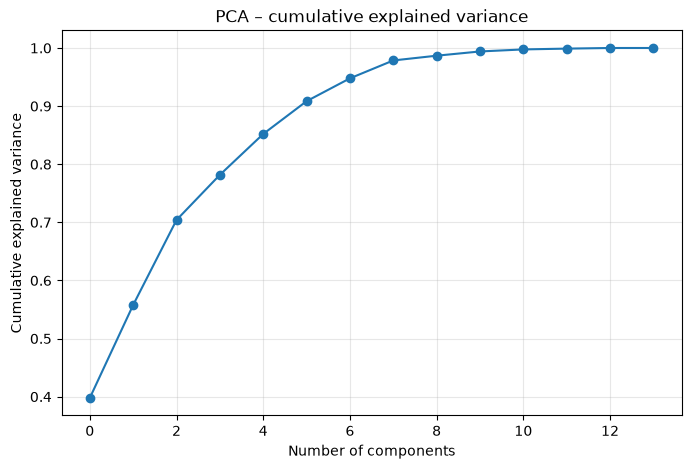

In [39]:
###################
#PCA
##################

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

#Explained variance
explained_variance = pca.explained_variance_ratio_

for i, variance in enumerate(explained_variance[:10], start=1):
    print(f"PC{i}: {variance:.2%}")

#plot cumulative explained variance

plt.figure(figsize=(8, 5))

plt.plot(
    np.cumsum(explained_variance),
    marker="o"
)

plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA – cumulative explained variance")
plt.grid(alpha=0.3)

plt.show()

#A principal component (PCA) is a weighted combination of the 37 variables added to the model.
#PC1 explains 39.77%
#That means the direction in the 37-dimensional feature space with the largest amount of variation between stations accounts for about 37% of the total variance.

#PC2 captures another 16%, and PC3 another 14.62%.

#Together:

#39.77% + 16% + 14.62% = 70.4%%
#So three dimensions capture about 70.4%% of the variation in the original 37-dimensional dataset.

#-----------
#Graph
#-----------

#It shows: How much of the original variation is retained if I keep the first N principal components?

#The first few PCs are doing a lot of work.

#The later PCs each contribute relatively little.

#THE ELBOW IS AROUND 3 OR 4 


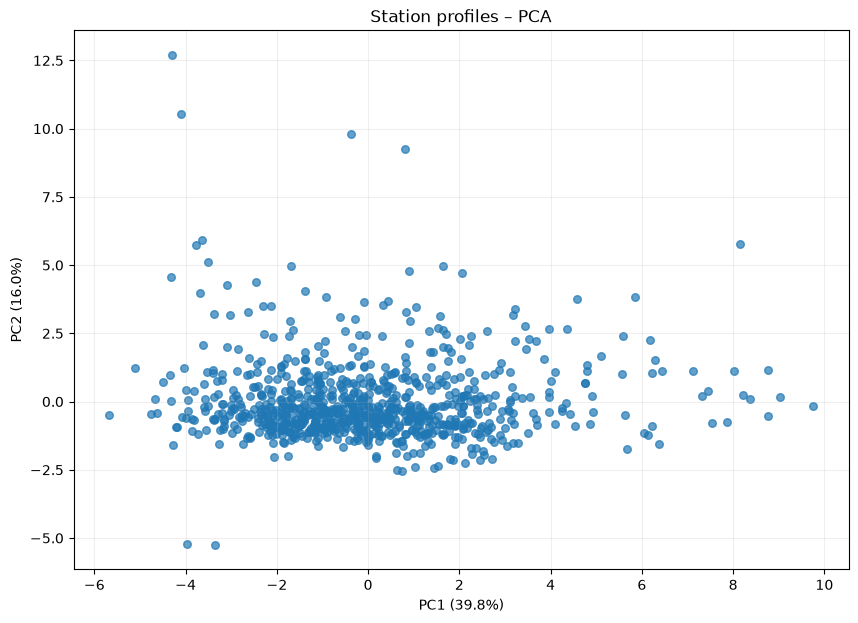

In [40]:
#Visualize stations in PCA space
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.7,
    s=30
)

plt.xlabel(f"PC1 ({explained_variance[0]:.1%})")
plt.ylabel(f"PC2 ({explained_variance[1]:.1%})")
plt.title("Station profiles – PCA")
plt.grid(alpha=0.2)

plt.show()

In [41]:
####################
#To interpret pca components
####################

#Get loadings
loadings = pl.DataFrame({
    "feature": feature_columns,
    "PC1": pca.components_[0].tolist(),
    "PC2": pca.components_[1].tolist(),
    "PC3": pca.components_[2].tolist(),
})

#sort PC1
print(
    loadings
    .sort("PC1", descending=True)
)

#And separately look at the largest absolute contributions:
pc1 = (
    loadings
    .with_columns(
        pl.col("PC1").abs().alias("abs_PC1")
    )
    .sort("abs_PC1", descending=True)
)

print(pc1)

#and pc2
pc2 = (
    loadings
    .with_columns(
        pl.col("PC2").abs().alias("abs_PC2")
    )
    .sort("abs_PC2", descending=True)
)

print(pc2)

#and pc3
pc3 = (
    loadings
    .with_columns(
        pl.col("PC3").abs().alias("abs_PC3")
    )
    .sort("abs_PC3", descending=True)
)

print(pc3)

#A loading tells you how strongly an original feature contributes to a principal component.

#PC1 appears to be a overall usage volume or how busy a station is
#PC1 has variables such as n_arrivals, avg_daily_arrivals, n_departures, avg_daily_departures, n_origins

#PC2 seems to be capturing temporal behaviour
#PC2 trip duration

#PC3 appears to be another temporal dimension
#PC3 Rush hours and weekend ratio


shape: (14, 4)
┌─────────────────────────┬───────────┬───────────┬───────────┐
│ feature                 ┆ PC1       ┆ PC2       ┆ PC3       │
│ ---                     ┆ ---       ┆ ---       ┆ ---       │
│ str                     ┆ f64       ┆ f64       ┆ f64       │
╞═════════════════════════╪═══════════╪═══════════╪═══════════╡
│ n_arrivals              ┆ 0.397054  ┆ 0.053247  ┆ -0.177033 │
│ avg_daily_arrivals      ┆ 0.392542  ┆ 0.068722  ┆ -0.170212 │
│ n_departures            ┆ 0.384622  ┆ 0.060291  ┆ -0.255257 │
│ avg_daily_departures    ┆ 0.379464  ┆ 0.0764    ┆ -0.24995  │
│ n_origins               ┆ 0.370287  ┆ -0.017095 ┆ 0.039038  │
│ …                       ┆ …         ┆ …         ┆ …         │
│ mean_duration           ┆ -0.04427  ┆ 0.610199  ┆ 0.143442  │
│ night_ratio             ┆ -0.061268 ┆ 0.124044  ┆ -0.114545 │
│ departure_arrival_ratio ┆ -0.120411 ┆ 0.046154  ┆ -0.369399 │
│ weekend_ratio           ┆ -0.13555  ┆ 0.383027  ┆ -0.248834 │
│ morning_rush_ratio     

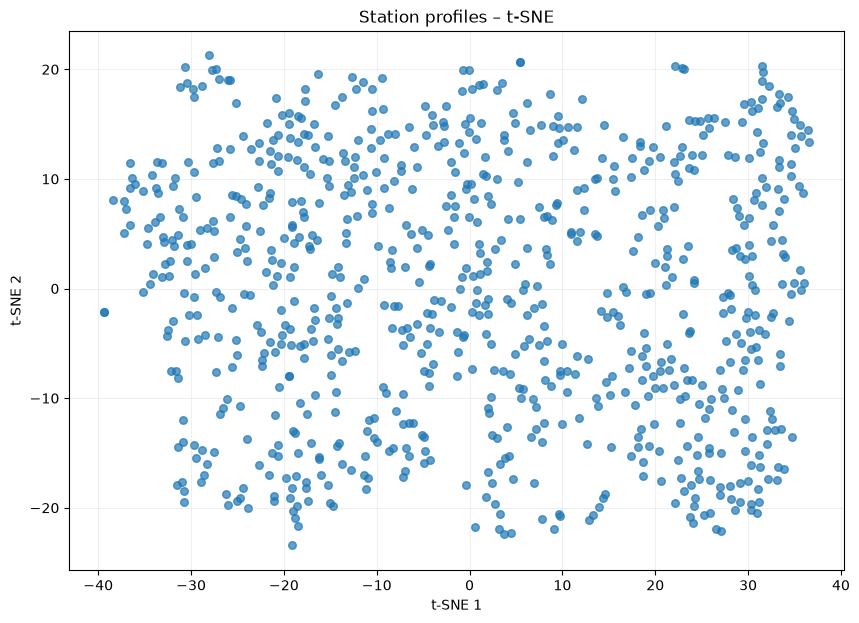

In [42]:
###########################
#Non linear dimension reduction: t-SNE
###########################

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

#plot
plt.figure(figsize=(10, 7))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    s=30,
    alpha=0.7
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Station profiles – t-SNE")
plt.grid(alpha=0.2)

plt.show()

#T-sne tries to do: stations that are close/similar in the original 33-dimensional space tend to remain close together in the 2D map.
#So t-SNE plot is essentially a map of station similarity.
#If two dots are close together: Their station profiles are relatively similar.
#If two dots are far apart: Their station profiles are relatively different.
#t-SNE is mainly good at showing: local neighbourhood structure

#----------------------------------------------
#In the graph: there are not very clear separated groups, maybe there are 3 or 4 different clouds?
#also, it doesnt seem to be a specially dense region nor isolated points

c:\Users\eliav\OneDrive\Documents\Julian\github\Dauphine\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


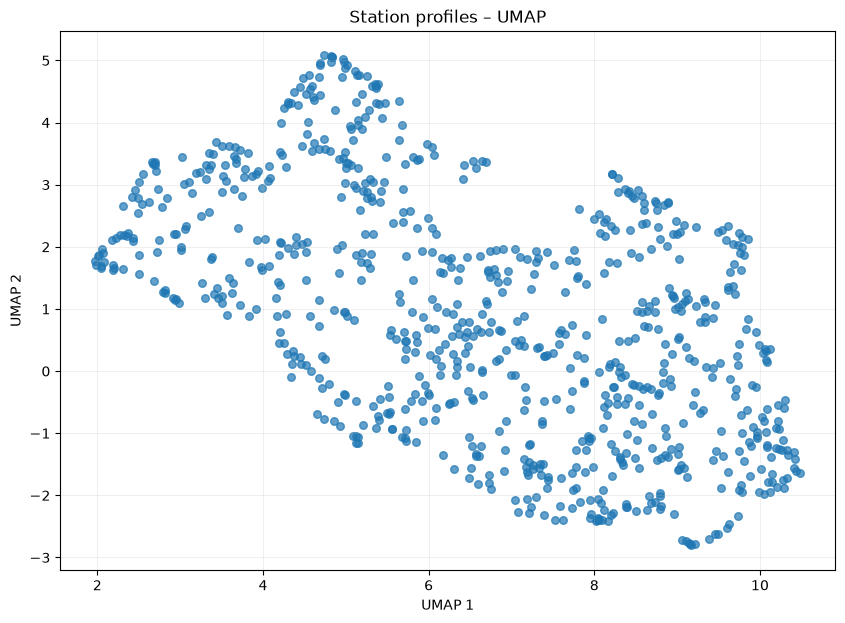

In [43]:
#And using umap
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

X_umap = reducer.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))

plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    s=30,
    alpha=0.7
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("Station profiles – UMAP")
plt.grid(alpha=0.2)

plt.show()

#UMAP = Uniform Manifold Approximation and Projection.
#The basic idea is: "If the 33-dimensional station profiles have some underlying structure, can I represent that structure in 2 dimensions while keeping similar stations close together?"

#Graph interpreation: relationships between points/regions


#---------------------------------------------------
#Here i dont see different clear groups, it looks more like a continous cloud which could mean that station behaviour changes gradually rather than forming naturally separated groups.

#UMAP was used as a nonlinear dimensionality-reduction technique to explore the structure of the station profiles. Unlike PCA, the two UMAP dimensions do not have a direct interpretation in terms of the original variables. 
#Instead, the projection is interpreted in terms of neighbourhood relationships, where nearby stations represent profiles with greater similarity. 
#The resulting projection was used as an exploratory visualisation and not as the basis for determining the number of clusters.

In [44]:
######################
#Identify natural groups
######################

#using K-means
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    results.append((k, score))

print(results)

#K-means finds its best separation at k = 2, but the silhouette score of 0.267 is relatively weak.
#This suggests that there are at most two broad groups in the data, but the station profiles do not naturally separate into very distinct clusters.

#since kmeans will always form groups we can say that Among the values of k tested, a two-cluster solution provides the strongest separation according to the silhouette criterion.

#current hypothesis:
#The 822 London stations do not form a set of sharply separated behavioural categories. 
#Instead, station usage appears to vary along several continuous temporal dimensions, with morning/evening activity, night-time activity,
#and weekend/midday activity being the strongest sources of variation. K-means identifies two broad groups as the best partition according
# to silhouette score, but the relatively low silhouette value indicates substantial overlap between the groups.



[(2, 0.26676211137492767), (3, 0.20967056943565066), (4, 0.21834460182770943), (5, 0.17481056499335093), (6, 0.17967714853812788), (7, 0.18084241114774585), (8, 0.1655068088211626), (9, 0.17227795623394998), (10, 0.15321323809759033)]


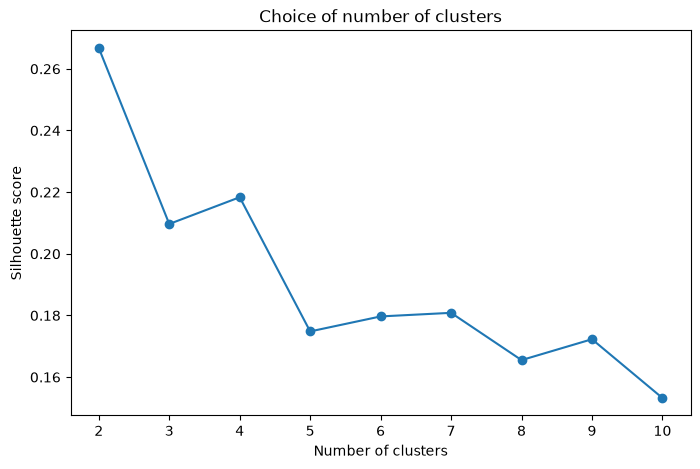

In [45]:
ks = [x[0] for x in results]
scores = [x[1] for x in results]

plt.figure(figsize=(8, 5))

plt.plot(ks, scores, marker="o")

plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("Choice of number of clusters")

plt.show()

#There is a peak on 2 clusters and has a secondary smaller peak at 4 clusters. It can be interesting to test 4 clusters rather than 2



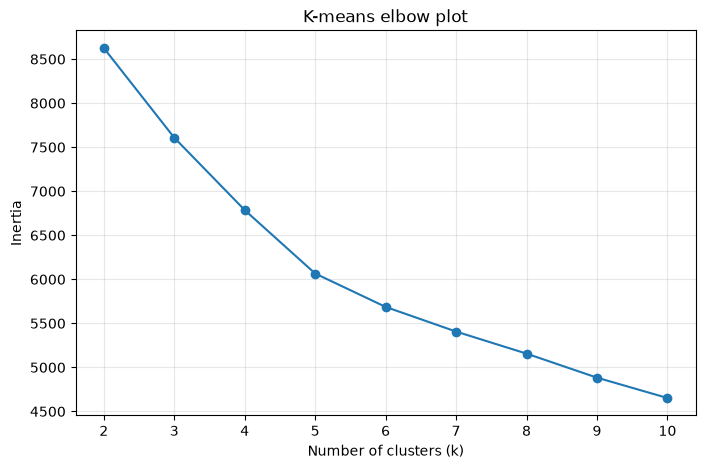

In [ ]:
######################
# Inertia - Elbow method
######################
inertias = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    model.fit(X_scaled)

    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertias,
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("K-means elbow plot")
plt.grid(alpha=0.3)

plt.show()

#It shows a smooth curve, there is however a change in 4 or 5 clusters. This is more evidence to chose 4 clusters rathern than 2


#  smooth, gradually flattening
# curve with no sharp elbow -- the mild flattening now sits around
# k=4-5 

In [ ]:
cluster_results = {}

for k in [2, 3, 4, 5, 6]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    cluster_results[k] = labels


for k, labels in cluster_results.items():

    counts = np.bincount(labels)
    percentages = (counts / len(labels)) * 100

    print(f"\nk={k}")
    for cluster, (count, percentage) in enumerate(zip(counts, percentages)):
        print(f"Cluster {cluster}: {count} ({percentage:.2f}%)")


#this gives us the number of stations that each cluster would have based on the k number we set


# k=2
# Cluster 0: 306 (37.23%)
# Cluster 1: 516 (62.77%)

# k=3
# Cluster 0: 321 (39.05%)
# Cluster 1: 67 (8.15%)
# Cluster 2: 434 (52.80%)

# k=4
# Cluster 0: 304 (36.98%)
# Cluster 1: 54 (6.57%)
# Cluster 2: 395 (48.05%)
# Cluster 3: 69 (8.39%)

# k=5
# Cluster 0: 273 (33.21%)
# Cluster 1: 50 (6.08%)
# Cluster 2: 66 (8.03%)
# Cluster 3: 171 (20.80%)
# Cluster 4: 262 (31.87%)

# k=6
# Cluster 0: 150 (18.25%)
# ...
# Cluster 2: 28 (3.41%)
# Cluster 3: 126 (15.33%)
# Cluster 4: 341 (41.48%)
# Cluster 5: 138 (16.79%)




k=2
Cluster 0: 306 (37.23%)
Cluster 1: 516 (62.77%)

k=3
Cluster 0: 321 (39.05%)
Cluster 1: 67 (8.15%)
Cluster 2: 434 (52.80%)

k=4
Cluster 0: 304 (36.98%)
Cluster 1: 54 (6.57%)
Cluster 2: 395 (48.05%)
Cluster 3: 69 (8.39%)

k=5
Cluster 0: 273 (33.21%)
Cluster 1: 50 (6.08%)
Cluster 2: 66 (8.03%)
Cluster 3: 171 (20.80%)
Cluster 4: 262 (31.87%)

k=6
Cluster 0: 150 (18.25%)
Cluster 1: 39 (4.74%)
Cluster 2: 28 (3.41%)
Cluster 3: 126 (15.33%)
Cluster 4: 341 (41.48%)
Cluster 5: 138 (16.79%)


In [34]:
#----------
#Calculate cluster profiles
#----------

for k in [2, 3, 4,5,6]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    profiles = stations.with_columns(
        pl.Series("cluster", labels.tolist())
    )

    cluster_means = (
        profiles
        .group_by("cluster")
        .agg([
            pl.col(feature).mean().alias(feature)
            for feature in feature_columns
        ])
        .sort("cluster")
    )

    print(f"\n===== k={k} =====")
    print(cluster_means)



===== k=2 =====
shape: (2, 15)
┌─────────┬────────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ cluster ┆ n_departur ┆ avg_daily ┆ n_arrival ┆ … ┆ weekend_r ┆ morning_r ┆ evening_r ┆ night_rat │
│ ---     ┆ es         ┆ _departur ┆ s         ┆   ┆ atio      ┆ ush_ratio ┆ ush_ratio ┆ io        │
│ i64     ┆ ---        ┆ es        ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│         ┆ f64        ┆ ---       ┆ f64       ┆   ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
│         ┆            ┆ f64       ┆           ┆   ┆           ┆           ┆           ┆           │
╞═════════╪════════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 0       ┆ 7795.78294 ┆ 22.270313 ┆ 7449.4360 ┆ … ┆ 0.252671  ┆ 0.269315  ┆ 0.200592  ┆ 0.028837  │
│         ┆ 6          ┆           ┆ 47        ┆   ┆           ┆           ┆           ┆           │
│ 1       ┆ 15489.3169 ┆ 43.185694 ┆ 16073.352 ┆ … ┆ 0.2057

In [35]:
# cluster centroids in standardised units.

for k in [2, 3, 4,5,6]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    kmeans.fit(X_scaled)

    centroid_df = pl.DataFrame(
        kmeans.cluster_centers_.tolist(),
        schema=feature_columns
    ).with_row_index("cluster")

    print(f"\n===== k={k} =====")
    print(centroid_df)

C:\Users\eliav\AppData\Local\Temp\ipykernel_28012\3840875654.py:13: DataOrientationWarning: Row orientation inferred during DataFrame construction. Explicitly specify the orientation by passing `orient="row"` to silence this warning.
  centroid_df = pl.DataFrame(
C:\Users\eliav\AppData\Local\Temp\ipykernel_28012\3840875654.py:13: DataOrientationWarning: Row orientation inferred during DataFrame construction. Explicitly specify the orientation by passing `orient="row"` to silence this warning.
  centroid_df = pl.DataFrame(
C:\Users\eliav\AppData\Local\Temp\ipykernel_28012\3840875654.py:13: DataOrientationWarning: Row orientation inferred during DataFrame construction. Explicitly specify the orientation by passing `orient="row"` to silence this warning.
  centroid_df = pl.DataFrame(



===== k=2 =====
shape: (2, 15)
┌─────────┬────────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ cluster ┆ n_departur ┆ avg_daily ┆ n_arrival ┆ … ┆ weekend_r ┆ morning_r ┆ evening_r ┆ night_rat │
│ ---     ┆ es         ┆ _departur ┆ s         ┆   ┆ atio      ┆ ush_ratio ┆ ush_ratio ┆ io        │
│ u32     ┆ ---        ┆ es        ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│         ┆ f64        ┆ ---       ┆ f64       ┆   ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
│         ┆            ┆ f64       ┆           ┆   ┆           ┆           ┆           ┆           │
╞═════════╪════════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 0       ┆ -0.457618  ┆ -0.456541 ┆ -0.484772 ┆ … ┆ 0.289682  ┆ 0.429985  ┆ -0.502418 ┆ 0.147487  │
│ 1       ┆ 0.77167    ┆ 0.769854  ┆ 0.817458  ┆ … ┆ -0.488483 ┆ -0.725073 ┆ 0.847214  ┆ -0.248704 │
└─────────┴────────────┴───────────┴───────────┴───┴───────

C:\Users\eliav\AppData\Local\Temp\ipykernel_28012\3840875654.py:13: DataOrientationWarning: Row orientation inferred during DataFrame construction. Explicitly specify the orientation by passing `orient="row"` to silence this warning.
  centroid_df = pl.DataFrame(
C:\Users\eliav\AppData\Local\Temp\ipykernel_28012\3840875654.py:13: DataOrientationWarning: Row orientation inferred during DataFrame construction. Explicitly specify the orientation by passing `orient="row"` to silence this warning.
  centroid_df = pl.DataFrame(


In [ ]:
#Features that distinguish clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

kmeans.fit(X_scaled)

centroids = kmeans.cluster_centers_

differences = pl.DataFrame({
    "feature": feature_columns,
    "difference": (centroids[0] - centroids[1]).tolist(),
}).with_columns(
    pl.col("difference").abs().alias("absolute_difference")
).sort(
    "absolute_difference",
    descending=True
)

print(differences)


#Variables with high variance (positive or negative) across the different K has a high impact on the separating work while low variance shows variables with almost no impact
#in this case we have variables like n_destinations and n_origins with high impact while mean_duration (of the trip) or night_ratio have low impact

centroid_spread = pl.DataFrame({
    "feature": feature_columns,
    "spread_across_clusters": centroids.std(axis=0).tolist(),
}).sort("spread_across_clusters", descending=True)

print(centroid_spread)


shape: (14, 3)
┌─────────────────────────┬────────────┬─────────────────────┐
│ feature                 ┆ difference ┆ absolute_difference │
│ ---                     ┆ ---        ┆ ---                 │
│ str                     ┆ f64        ┆ f64                 │
╞═════════════════════════╪════════════╪═════════════════════╡
│ n_destinations          ┆ -1.348759  ┆ 1.348759            │
│ n_origins               ┆ -1.311481  ┆ 1.311481            │
│ evening_rush_ratio      ┆ -1.271769  ┆ 1.271769            │
│ morning_rush_ratio      ┆ 1.162324   ┆ 1.162324            │
│ n_arrivals              ┆ -0.845542  ┆ 0.845542            │
│ …                       ┆ …          ┆ …                   │
│ departure_arrival_ratio ┆ 0.548589   ┆ 0.548589            │
│ night_ratio             ┆ 0.161921   ┆ 0.161921            │
│ median_duration         ┆ -0.142429  ┆ 0.142429            │
│ std_duration            ┆ -0.120274  ┆ 0.120274            │
│ mean_duration           ┆ -0.023359  ┆

In [ ]:
#Select K value after analysis
k_clusters = 4
#since this is a clustering project, its more interesting to cluster based on the result of 4 clusters rather than 2, 
# even thou 2 clusters is the number that better fits the results obtained

kmeans = KMeans(
    n_clusters=k_clusters,
    random_state=42,
    n_init=20
)

labels = kmeans.fit_predict(X_scaled)


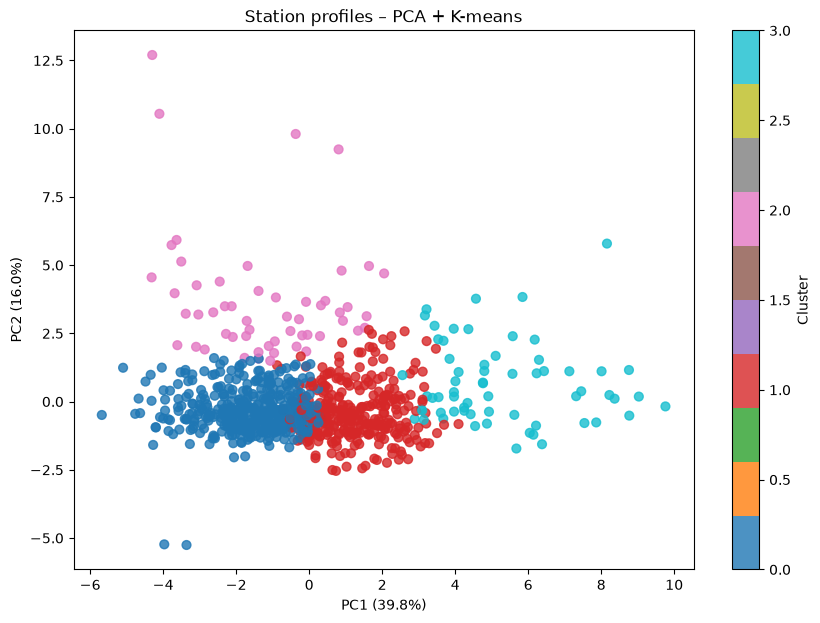

In [ ]:
################3
#Color PCA plot by cluster
#################

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="tab10",
    s=40,
    alpha=0.8
)

plt.xlabel(f"PC1 ({explained_variance[0]:.1%})")
plt.ylabel(f"PC2 ({explained_variance[1]:.1%})")
plt.title("Station profiles – PCA + K-means")

plt.colorbar(scatter, label="Cluster")

plt.show()

#We can see a clear separtion of the 4 clusters in the graph

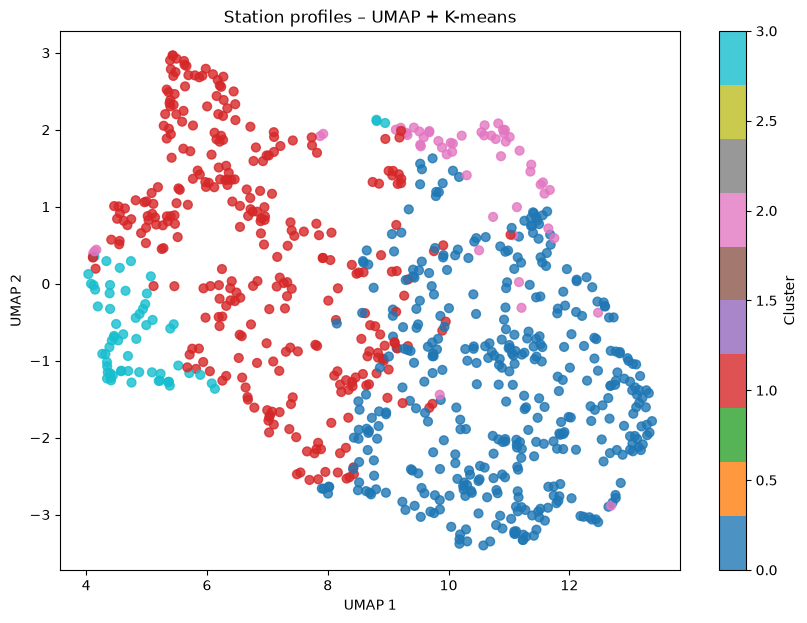

In [ ]:
#and same for umap
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=labels,
    cmap="tab10",
    s=40,
    alpha=0.8
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("Station profiles – UMAP + K-means")

plt.colorbar(scatter, label="Cluster")

plt.show()

#Here the separation of the clusters is also visible. There are however some stations mixed between clusters (light blue and pink clusters in the center-top)

In [ ]:
closest, distances = pairwise_distances_argmin_min(
    X_scaled,
    kmeans.cluster_centers_
)

stations_analysis = stations.with_columns([
    pl.Series("cluster", labels),
    pl.Series("distance_to_cluster_center", distances)
])


In [ ]:
##############
#Find atypical or isolated stations
###############

#-------------
# distance from the cluster centroid
#-------------

cluster_thresholds = (
    stations_analysis
    .group_by("cluster")
    .agg(
        pl.col("distance_to_cluster_center")
        .quantile(0.99)
        .alias("outlier_threshold")
    )
)

outliers = (
    stations_analysis
    .join(cluster_thresholds, on="cluster")
    .filter(
        pl.col("distance_to_cluster_center")
        >= pl.col("outlier_threshold")
    )
    .sort("distance_to_cluster_center", descending=True)
)

print(
    outliers.select([
        "station",
        "cluster",
        "distance_to_cluster_center",
        "outlier_threshold"
    ])
)


# we get flags 14 rows out of 822 stations.
# Two of them are both "station 0" (distances 12.01 and 11.82, both the
# single most extreme point in cluster 1, well above its 6.02
# threshold). These 2 stations are most likely not real. They seem to be an error in the creation of the full df that needs to be corrected

shape: (13, 4)
┌───────────┬─────────┬────────────────────────────┬───────────────────┐
│ station   ┆ cluster ┆ distance_to_cluster_center ┆ outlier_threshold │
│ ---       ┆ ---     ┆ ---                        ┆ ---               │
│ i64       ┆ i32     ┆ f64                        ┆ f64               │
╞═══════════╪═════════╪════════════════════════════╪═══════════════════╡
│ 1101      ┆ 2       ┆ 14.169563                  ┆ 12.321502         │
│ 200009    ┆ 2       ┆ 12.321502                  ┆ 12.321502         │
│ 0         ┆ 0       ┆ 12.243107                  ┆ 5.020935          │
│ 0         ┆ 0       ┆ 12.007993                  ┆ 5.020935          │
│ 1072      ┆ 3       ┆ 10.727519                  ┆ 7.336099          │
│ …         ┆ …       ┆ …                          ┆ …                 │
│ 2692      ┆ 1       ┆ 6.23297                    ┆ 4.73363           │
│ 1035      ┆ 1       ┆ 5.211659                   ┆ 4.73363           │
│ 200191444 ┆ 0       ┆ 5.020935    

In [ ]:
print(
    stations_analysis.select([
        pl.col("distance_to_cluster_center").quantile(0.50).alias("median"),
        pl.col("distance_to_cluster_center").quantile(0.75).alias("q75"),
        pl.col("distance_to_cluster_center").quantile(0.90).alias("q90"),
        pl.col("distance_to_cluster_center").quantile(0.95).alias("q95"),
        pl.col("distance_to_cluster_center").quantile(0.99).alias("q99"),
    ])
)

#The stations identified as atypical are those in the upper 1% of distances to their cluster centroid.
#The threshold is selected like this beacuse The jump from q95 (4.35) to q99 (7.31) is much
# bigger than from q90 (3.75) to q95. this shows the distance distribution has a
# long tail, consistent with a handful of real outlier stations rather
# than a gradual spread.


shape: (1, 5)
┌──────────┬──────────┬──────────┬──────────┬──────────┐
│ median   ┆ q75      ┆ q90      ┆ q95      ┆ q99      │
│ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞══════════╪══════════╪══════════╪══════════╪══════════╡
│ 2.328161 ┆ 3.020287 ┆ 3.979979 ┆ 4.570392 ┆ 7.336099 │
└──────────┴──────────┴──────────┴──────────┴──────────┘


In [ ]:
#---------------------
#Isolation forest
#---------------------
from sklearn.ensemble import IsolationForest

iso = IsolationForest(
    contamination=0.01,
    random_state=42
)

outlier_labels = iso.fit_predict(X_scaled)

stations_iforest = stations.with_columns(
    pl.Series("isolation_outlier", outlier_labels.tolist())
)

outliers_iforest = (
    stations_iforest
    .filter(pl.col("isolation_outlier") == -1)
)

print(
    outliers_iforest.select("station")
)

#The fake station 0 appears here again. If we ignore them we get other 7 real stations (1072, 1075,
# 2635, 200009, 2696, 200233, 1101) that partially overlap with the
# distance-based outliers above (1072, 2696, 1101 appear in both lists)


shape: (9, 1)
┌─────────┐
│ station │
│ ---     │
│ i64     │
╞═════════╡
│ 0       │
│ 1075    │
│ 1072    │
│ 960     │
│ 2696    │
│ 200233  │
│ 0       │
│ 1101    │
│ 2587    │
└─────────┘


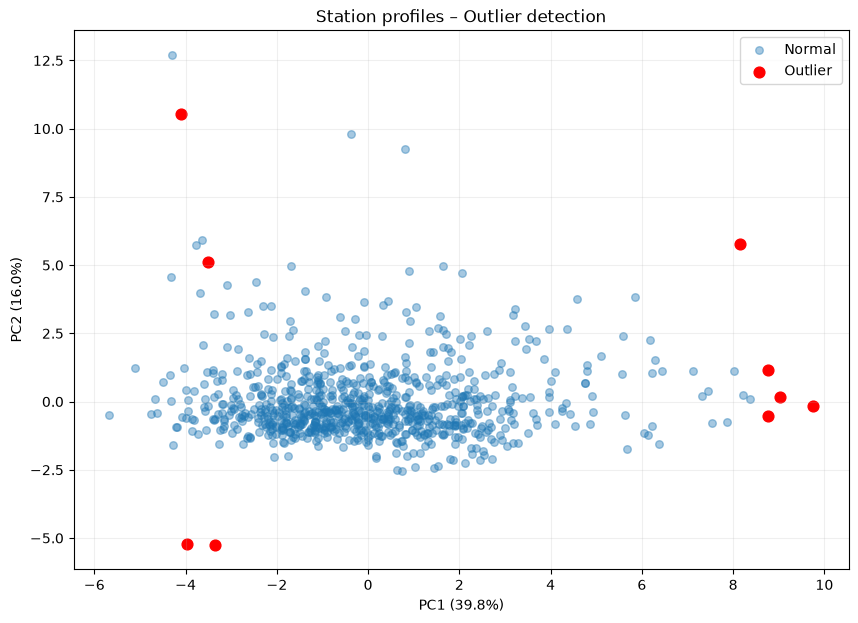

In [44]:
#---------------
#Outliers graph
#---------------

plt.figure(figsize=(10, 7))

normal = outlier_labels == 1
outlier = outlier_labels == -1

plt.scatter(
    X_pca[normal, 0],
    X_pca[normal, 1],
    alpha=0.4,
    s=30,
    label="Normal"
)

plt.scatter(
    X_pca[outlier, 0],
    X_pca[outlier, 1],
    color="red",
    s=60,
    label="Outlier"
)

plt.xlabel(f"PC1 ({explained_variance[0]:.1%})")
plt.ylabel(f"PC2 ({explained_variance[1]:.1%})")
plt.title("Station profiles – Outlier detection")
plt.legend()
plt.grid(alpha=0.2)

plt.show()


In [ ]:
#--------------------------
#Very low or high activity
#--------------------------
#check distribution
print(stations.select([
    pl.col("n_departures").quantile(0.01).alias("p01"),
    pl.col("n_departures").quantile(0.05).alias("p05"),
    pl.col("n_departures").median().alias("median"),
    pl.col("n_departures").quantile(0.95).alias("p95"),
    pl.col("n_departures").quantile(0.99).alias("p99"),
]))

#Identify station in the top 1% of departures
q01_dep = stations["n_departures"].quantile(0.01)
q99_dep = stations["n_departures"].quantile(0.99)

activity_outliers_dep = stations.filter(
    (pl.col("n_departures") <= q01_dep) |
    (pl.col("n_departures") >= q99_dep)
)

#Identify station in the top 1% of arrivals
q01_arr = stations["n_arrivals"].quantile(0.01)
q99_arr = stations["n_arrivals"].quantile(0.99)

activity_outliers_arr = stations.filter(
    (pl.col("n_arrivals") <= q01_arr) |
    (pl.col("n_arrivals") >= q99_arr)
)

# Total activity = departures + arrivals
stations = stations.with_columns(
    (
        pl.col("n_departures") + pl.col("n_arrivals")
    ).alias("total_activity")
)

# 1st and 99th percentiles
q01_activity = stations["total_activity"].quantile(0.01)
q99_activity = stations["total_activity"].quantile(0.99)

# Identify unusually low or high activity stations
activity_outliers = stations.filter(
    (pl.col("total_activity") <= q01_activity) |
    (pl.col("total_activity") >= q99_activity)
)



print(
    activity_outliers.select([
        "station",
        "n_departures",
        "n_arrivals",
        "total_activity"
    ])
)


# This flags 18 stations combining the bottom and top 1% of total
# activity (departures + arrivals). At the top: station 1072
# (104,443 trips/year) and 1075 (79,668) -- consistent with them
# showing up as hubs in every other method in this notebook and in the
# origin-destination notebook's weighted-degree rankings. At the
# bottom: real, very low-traffic stations like 2635 (64 trips/year
# total) sit alongside "station 0" again. 

shape: (1, 5)
┌───────┬────────┬────────┬─────────┬─────────┐
│ p01   ┆ p05    ┆ median ┆ p95     ┆ p99     │
│ ---   ┆ ---    ┆ ---    ┆ ---     ┆ ---     │
│ f64   ┆ f64    ┆ f64    ┆ f64     ┆ f64     │
╞═══════╪════════╪════════╪═════════╪═════════╡
│ 841.0 ┆ 2950.0 ┆ 9550.0 ┆ 21933.0 ┆ 32640.0 │
└───────┴────────┴────────┴─────────┴─────────┘
shape: (18, 4)
┌───────────┬──────────────┬────────────┬────────────────┐
│ station   ┆ n_departures ┆ n_arrivals ┆ total_activity │
│ ---       ┆ ---          ┆ ---        ┆ ---            │
│ i64       ┆ u32          ┆ u32        ┆ u32            │
╞═══════════╪══════════════╪════════════╪════════════════╡
│ 200083444 ┆ 488          ┆ 554        ┆ 1042           │
│ 0         ┆ 0            ┆ 607        ┆ 607            │
│ 1075      ┆ 42737        ┆ 36931      ┆ 79668          │
│ 1072      ┆ 53880        ┆ 50563      ┆ 104443         │
│ 2635      ┆ 37           ┆ 27         ┆ 64             │
│ …         ┆ …            ┆ …          ┆ …  

In [ ]:
#--------------------
#Extreme departures/arrivales ration
#--------------------

stations_ratio = stations.with_columns(
    (
        pl.col("n_departures") /
        (pl.col("n_departures") + pl.col("n_arrivals"))
    ).alias("departure_share")
)

print(
    stations_ratio
    .sort("departure_share")
    .select([
        "station",
        "n_departures",
        "n_arrivals",
        "departure_share"
    ])
    .head(10)
)

print(
    stations_ratio
    .sort("departure_share", descending=True)
    .select([
        "station",
        "n_departures",
        "n_arrivals",
        "departure_share"
    ])
    .head(10)
)

#close to 0.5 → balanced
#close to 1 → mostly departures
#close to 0 → mostly arrivals

#Station 0 sits in the first postion again. If we ignore we get the real most arrival-skewed station is 200226 at 0.375, and the most
# departure-skewed is 1101 at 0.726 which is consistent
# with 1101 and 200017 also showing up as strongly one-directional in
# the origin-destination notebook's flow-imbalance ranking.


shape: (10, 4)
┌─────────┬──────────────┬────────────┬─────────────────┐
│ station ┆ n_departures ┆ n_arrivals ┆ departure_share │
│ ---     ┆ ---          ┆ ---        ┆ ---             │
│ i64     ┆ u32          ┆ u32        ┆ f64             │
╞═════════╪══════════════╪════════════╪═════════════════╡
│ 0       ┆ 0            ┆ 607        ┆ 0.0             │
│ 0       ┆ 0            ┆ 199        ┆ 0.0             │
│ 200226  ┆ 10824        ┆ 18015      ┆ 0.375325        │
│ 982     ┆ 19593        ┆ 30817      ┆ 0.388673        │
│ 2688    ┆ 6265         ┆ 9062       ┆ 0.408756        │
│ 200072  ┆ 10838        ┆ 15551      ┆ 0.410701        │
│ 1067    ┆ 28981        ┆ 40483      ┆ 0.417209        │
│ 1061    ┆ 4564         ┆ 6352       ┆ 0.418102        │
│ 3431    ┆ 5616         ┆ 7679       ┆ 0.422414        │
│ 200253  ┆ 7301         ┆ 9965       ┆ 0.422854        │
└─────────┴──────────────┴────────────┴─────────────────┘
shape: (10, 4)
┌─────────┬──────────────┬────────────┬───

In [ ]:
#----------------
#atypical hour profile
#----------------
stations_pca = stations.with_columns([
    pl.Series("PC1", X_pca[:, 0].tolist()),
    pl.Series("PC2", X_pca[:, 1].tolist()),
    pl.Series("PC3", X_pca[:, 2].tolist())
])


print(
    stations_pca.sort("PC1").select([
        "station",
        "PC1",
        "PC2",
        "PC3"
    ]).head(10)
)
print(
    stations_pca.sort("PC1", descending=True).select([
        "station",
        "PC1",
        "PC2",
        "PC3"
    ]).head(10)
)


#Which stations have an unusual distribution of activity throughout the day?

#Your PCA showed:

#PC1 ≈ usage volume / quantity -> attypical means station not very used
#PC2 ≈ night/early morning behaviour -> attypical means unsual time of day
#PC3 ≈ midday/weekend behaviour -> attypical means unsual time of day or weekend
#So a station with an extreme PCA score can potentially be considered temporally atypical or underused vs other stations.



shape: (10, 4)
┌───────────┬───────────┬───────────┬───────────┐
│ station   ┆ PC1       ┆ PC2       ┆ PC3       │
│ ---       ┆ ---       ┆ ---       ┆ ---       │
│ i64       ┆ f64       ┆ f64       ┆ f64       │
╞═══════════╪═══════════╪═══════════╪═══════════╡
│ 2635      ┆ -5.68122  ┆ -0.490199 ┆ 0.171753  │
│ 11274444  ┆ -5.098073 ┆ 1.239947  ┆ -0.204356 │
│ 1219444   ┆ -4.766159 ┆ -0.448517 ┆ -1.054641 │
│ 200191444 ┆ -4.672575 ┆ 0.109494  ┆ 1.054403  │
│ 200254    ┆ -4.631573 ┆ -0.422509 ┆ -0.14449  │
│ 300084    ┆ -4.483401 ┆ 0.734288  ┆ 0.986553  │
│ 200224    ┆ -4.342186 ┆ 0.981766  ┆ 0.488762  │
│ 1111      ┆ -4.317667 ┆ 0.028877  ┆ -0.102622 │
│ 200092    ┆ -4.315875 ┆ 4.551307  ┆ 1.530084  │
│ 200009    ┆ -4.299624 ┆ 12.70011  ┆ 3.371314  │
└───────────┴───────────┴───────────┴───────────┘
shape: (10, 4)
┌─────────┬──────────┬───────────┬───────────┐
│ station ┆ PC1      ┆ PC2       ┆ PC3       │
│ ---     ┆ ---      ┆ ---       ┆ ---       │
│ i64     ┆ f64      ┆ f64   

In [ ]:
#################33
#Make clusters interpretables
##################

cluster_summary = (
    stations_analysis
    .group_by("cluster")
    .agg([
        pl.col(c).mean().alias(c)
        for c in feature_columns
    ])
)

print(cluster_summary)

# Cluster 3 stands out with by far the highest volume (mean
# n_departures=25,472, n_arrivals=26,930) and the highest
# evening_rush_ratio (0.307) but the lowest weekend_ratio (0.221) --
# these are the busy, commute-driven hub stations (matching PC1="usage
# volume" and the hub stations flagged throughout the atypical-stations
# section above, e.g. 1072, 2696, 2587). Cluster 4 has the highest
# evening_rush_ratio of all (0.375) combined with the lowest
# morning_rush_ratio (0.100) and lowest weekend_ratio (0.182) -- a
# clearly evening/commute-skewed profile. Cluster 2 has the highest
# weekend_ratio (0.292) and a comparatively low evening_rush_ratio
# (0.236) -- more leisure/weekend-driven, lower-volume stations.

shape: (4, 15)
┌─────────┬────────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ cluster ┆ n_departur ┆ avg_daily ┆ n_arrival ┆ … ┆ weekend_r ┆ morning_r ┆ evening_r ┆ night_rat │
│ ---     ┆ es         ┆ _departur ┆ s         ┆   ┆ atio      ┆ ush_ratio ┆ ush_ratio ┆ io        │
│ i32     ┆ ---        ┆ es        ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│         ┆ f64        ┆ ---       ┆ f64       ┆   ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
│         ┆            ┆ f64       ┆           ┆   ┆           ┆           ┆           ┆           │
╞═════════╪════════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 1       ┆ 12315.1791 ┆ 34.315126 ┆ 12506.296 ┆ … ┆ 0.206906  ┆ 0.158753  ┆ 0.309434  ┆ 0.025489  │
│         ┆ 53         ┆           ┆ 417       ┆   ┆           ┆           ┆           ┆           │
│ 2       ┆ 8283.85185 ┆ 25.334408 ┆ 8103.1666 ┆ … ┆ 0.295419  ┆ 0.19955   ┆

****CLUSTERING ORIGIN DESTINATION****



In [ ]:
#In case needed
df = pl.read_parquet("../data/output/v2/2.clean_df_v2.parquet")

print(df.head())

shape: (5, 14)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ Start     ┆ Start     ┆ End date  ┆ End       ┆ … ┆ start_sta ┆ end_stati ┆ end_stati ┆ end_stat │
│ date      ┆ station   ┆ ---       ┆ station   ┆   ┆ tion_name ┆ on_latitu ┆ on_longit ┆ ion_name │
│ ---       ┆ number    ┆ datetime[ ┆ number    ┆   ┆ ---       ┆ de        ┆ ude       ┆ ---      │
│ datetime[ ┆ ---       ┆ μs]       ┆ ---       ┆   ┆ str       ┆ ---       ┆ ---       ┆ str      │
│ μs]       ┆ i64       ┆           ┆ i64       ┆   ┆           ┆ f64       ┆ f64       ┆          │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 2025-01-1 ┆ 1043      ┆ 2025-01-1 ┆ 200149    ┆ … ┆ Museum of ┆ 51.511542 ┆ -0.056667 ┆ Watney   │
│ 4         ┆           ┆ 5         ┆           ┆   ┆ London,   ┆           ┆           ┆ Street,  │
│ 23:59:00  ┆           ┆ 00:13:00  ┆           ┆   ┆ Barbican  ┆           

In [4]:
# Aggregate trips from station i -> station j
edges = (
    df
    .group_by([
        "Start station number",
        "End station number"
    ])
    .agg(
        pl.len().alias("weight")
    )
    .rename({
        "Start station number": "source",
        "End station number": "target"
    })
    .sort("weight", descending=True)
)

print(edges.head())
print(edges.shape)

shape: (5, 3)
┌────────┬────────┬────────┐
│ source ┆ target ┆ weight │
│ ---    ┆ ---    ┆ ---    │
│ i64    ┆ i64    ┆ u32    │
╞════════╪════════╪════════╡
│ 1075   ┆ 1132   ┆ 3156   │
│ 300213 ┆ 300234 ┆ 2851   │
│ 1132   ┆ 1075   ┆ 2807   │
│ 300234 ┆ 300213 ┆ 2756   │
│ 200038 ┆ 200230 ┆ 2535   │
└────────┴────────┴────────┘
(462168, 3)


In [5]:
stations_start = df.select(
    pl.col("Start station number")
    .drop_nulls()
    .unique()
    .alias("station")
)

stations_end = df.select(
    pl.col("End station number")
    .drop_nulls()
    .unique()
    .alias("station")
)

nodes = (
    pl.concat([stations_start, stations_end])
    .unique()
    .sort("station")
)

print(f"Number of stations : {nodes.height}")

Number of stations : 822


In [ ]:
#Create graph

G = nx.DiGraph()

# Add all stations, including stations that might have
# only incoming or only outgoing trips

G.add_nodes_from(nodes["station"].to_list())


# Add weighted directed edges
G.add_weighted_edges_from(
    edges.select(["source", "target", "weight"]).iter_rows()
)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())


# G = (V,E)

#avec :
#V= stations ;
#E = couples of stations that have at least one observed trip
#Wij= number of trips from i to j

Number of nodes: 822
Number of edges: 462168


In [ ]:
#basic descriptions of the graph


#Number of nodes and edges
n_nodes = G.number_of_nodes()
n_edges = G.number_of_edges()

#Total trips
total_trips = sum(
    data["weight"]
    for _, _, data in G.edges(data=True)
)

print(f"Number of stations: {n_nodes}")
print(f"Number of directed edges: {n_edges}")
print(f"Number of total trips: {total_trips:,}")



#Graph density
density = nx.density(G)

print(f"Directed graph density: {density:.4f}")


# 0.68 means most of the 822*821 ≈ 675k possible directed pairs actually
# have at least one recorded trip between them over the year. This is
# expected for a dense bike-share system (any station can in principle
# be reached from any other), but it also means the network is close to
# "everyone is connected to almost everyone" -- so unweighted structure
# (who is connected to whom) carries little information; the weights
# (how many trips) are where the real signal is

Number of stations: 822
Number of directed edges: 462168
Number of total trips: 8,762,355
Directed graph density: 0.6848


In [ ]:
##################
#Degree distribution
##################

#Unweighted degree
#This measures the number of different stations connected to a station
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

degree_df = pl.DataFrame({
    "station": list(G.nodes()),
    "in_degree": [in_degree[s] for s in G.nodes()],
    "out_degree": [out_degree[s] for s in G.nodes()],
})

print("In-degree:")
print(degree_df.select("in_degree").describe())

print("Out-degree:")
print(degree_df.select("out_degree").describe())


# typical stations are already directly connected (in at least
# one direction, at least once over the year) to about 68% of all other
# stations -- consistent with the 0.68 density noted above. 

In-degree:
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ in_degree  │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 822.0      │
│ null_count ┆ 0.0        │
│ mean       ┆ 562.248175 │
│ std        ┆ 128.07283  │
│ min        ┆ 15.0       │
│ 25%        ┆ 483.0      │
│ 50%        ┆ 576.0      │
│ 75%        ┆ 655.0      │
│ max        ┆ 799.0      │
└────────────┴────────────┘
Out-degree:
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ out_degree │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 822.0      │
│ null_count ┆ 0.0        │
│ mean       ┆ 562.248175 │
│ std        ┆ 135.934907 │
│ min        ┆ 0.0        │
│ 25%        ┆ 474.0      │
│ 50%        ┆ 577.0      │
│ 75%        ┆ 665.0      │
│ max        ┆ 807.0      │
└────────────┴────────────┘


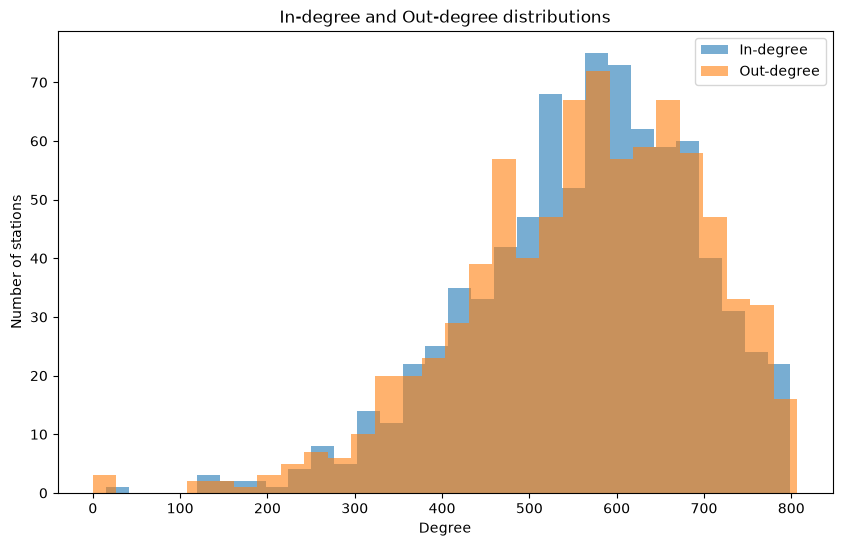

In [9]:
#unweighted plot
plt.figure(figsize=(10, 6))

plt.hist(
    list(in_degree.values()),
    bins=30,
    alpha=0.6,
    label="In-degree"
)

plt.hist(
    list(out_degree.values()),
    bins=30,
    alpha=0.6,
    label="Out-degree"
)

plt.xlabel("Degree")
plt.ylabel("Number of stations")
plt.title("In-degree and Out-degree distributions")
plt.legend()
plt.show()

In [ ]:

#Weighted degree / strength
#This gives the stations generating/receiving the largest numbers of trips.

weighted_in_degree = dict(G.in_degree(weight="weight"))
weighted_out_degree = dict(G.out_degree(weight="weight"))

station_df = pl.DataFrame({
    "station": list(G.nodes()),
    "in_degree": [in_degree[s] for s in G.nodes()],
    "out_degree": [out_degree[s] for s in G.nodes()],
    "weighted_in_degree": [
        weighted_in_degree[s] for s in G.nodes()
    ],
    "weighted_out_degree": [
        weighted_out_degree[s] for s in G.nodes()
    ],
})

print("In-degree weighted:")
print(station_df.select("weighted_in_degree").describe())

print("Out-degree weighted:")
print(station_df.select("weighted_out_degree").describe())

# Mean weighted in/out-degree is identical (10,659.8) because every trip
# counted as an outflow of its start station is also counted as an
# inflow of its end station -- total inflow across the network always
# equals total outflow. 

# The spread is large though: std ~6,600, and the
# busiest station receives 50,563 trips/year (max weighted_in_degree)
# vs. a quietest station with only 27 -- almost a 2,000x gap in traffic
# between the busiest and quietest stations, even though nearly every
# station is *connected* to nearly every other one

In-degree weighted:
shape: (9, 2)
┌────────────┬────────────────────┐
│ statistic  ┆ weighted_in_degree │
│ ---        ┆ ---                │
│ str        ┆ f64                │
╞════════════╪════════════════════╡
│ count      ┆ 822.0              │
│ null_count ┆ 0.0                │
│ mean       ┆ 10659.79927        │
│ std        ┆ 6626.45292         │
│ min        ┆ 27.0               │
│ 25%        ┆ 6514.0             │
│ 50%        ┆ 9295.0             │
│ 75%        ┆ 13197.0            │
│ max        ┆ 50563.0            │
└────────────┴────────────────────┘
Out-degree weighted:
shape: (9, 2)
┌────────────┬─────────────────────┐
│ statistic  ┆ weighted_out_degree │
│ ---        ┆ ---                 │
│ str        ┆ f64                 │
╞════════════╪═════════════════════╡
│ count      ┆ 822.0               │
│ null_count ┆ 0.0                 │
│ mean       ┆ 10659.79927         │
│ std        ┆ 6262.33475          │
│ min        ┆ 0.0                 │
│ 25%        ┆ 6745.0

In [ ]:
#distribution of edge weights
#The edge weight is:
#the number of observed trips from station i to station j.
weights = [
    data["weight"]
    for _, _, data in G.edges(data=True)
]

#descriptive stats
weights_series = pl.Series("weight", weights)

print(weights_series.describe())

#percentiles
print(
    weights_series.quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)



# Median edge weight is 6 trips/year but the mean is 18.96 -- pulled up
# by a long tail (max 3,156 trips on a single station pair). Even the
# 90th percentile is only 46, so the vast majority of the 462,168
# station-pair connections are "connected but rarely used" (a handful of
# trips over the whole year), while a small number of pairs (likely
# geographically close or on popular commuting routes) carry a
# disproportionate share of traffic.
# 
# Using a log-log plot can be useful in this case to check the long tail mentioned

shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 462168.0  │
│ null_count ┆ 0.0       │
│ mean       ┆ 18.959242 │
│ std        ┆ 46.05024  │
│ min        ┆ 1.0       │
│ 25%        ┆ 2.0       │
│ 50%        ┆ 6.0       │
│ 75%        ┆ 18.0      │
│ max        ┆ 3156.0    │
└────────────┴───────────┘
[2.0, 6.0, 18.0, 46.0, 78.0, 190.0]


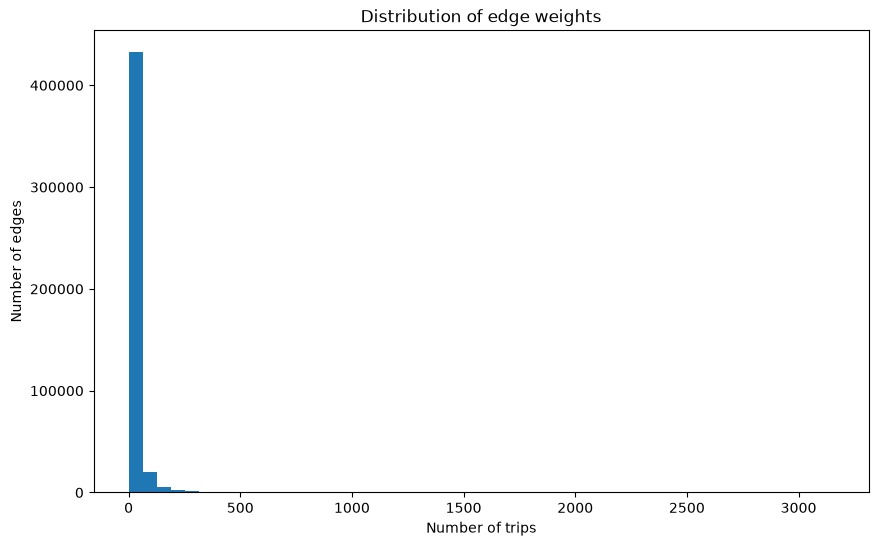

In [12]:
#Edge weights distribution plot
plt.figure(figsize=(10, 6))

plt.hist(weights, bins=50)

plt.xlabel("Number of trips")
plt.ylabel("Number of edges")
plt.title("Distribution of edge weights")

plt.show()

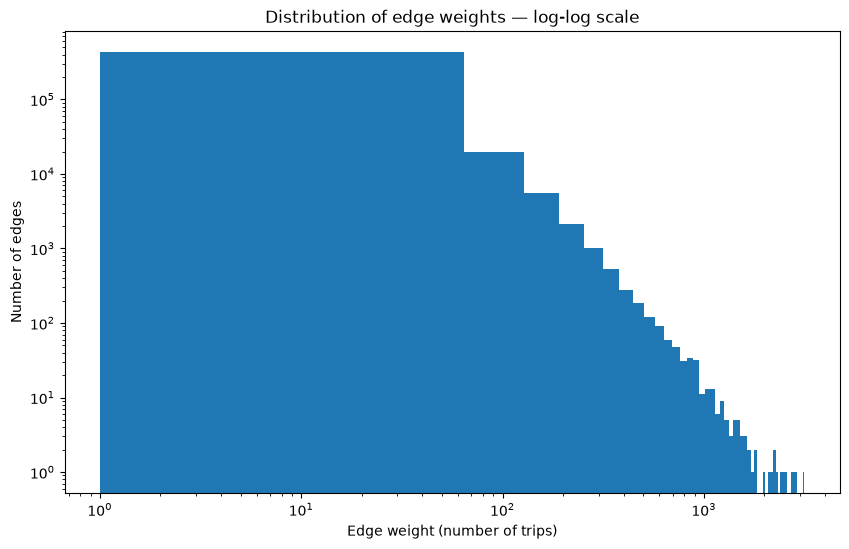

In [13]:
#log graph
plt.figure(figsize=(10, 6))

plt.hist(weights, bins=50)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Edge weight (number of trips)")
plt.ylabel("Number of edges")
plt.title("Distribution of edge weights — log-log scale")

plt.show()

In [ ]:
###############
#Central stations
###############
#using degree centrality
degree_centrality = nx.degree_centrality(G)

top_degree = sorted(
    degree_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("Top 10 stations by degree centrality:")

for station, value in top_degree:
    print(station, value)

    

# values close to 2 here just mean these
# stations are connected (in either direction) to almost every other
# station in both directions. That matches the 0.68 density noted
# earlier: with the graph this dense, unweighted degree centrality
# barely separates stations (top 10 all sit within ~0.03 of each other,
# 995 at 1.945 vs 1028 at 1.917).

Top 10 stations by degree centrality:
1052 1.9500609013398293
995 1.9451887941534713
1160 1.9427527405602922
200128 1.9403166869671131
1011 1.9354445797807551
1151 1.925700365408039
300249 1.925700365408039
3504 1.9244823386114494
960 1.9183922046285018
1028 1.9171741778319122


In [15]:
#Weighted flow centrality
top_inflow = sorted(
    weighted_in_degree.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("Top 10 stations by incoming flow:")

for station, value in top_inflow:
    print(f"{station}: {value:,} trips")

#Stations with most trips
top_outflow = sorted(
    weighted_out_degree.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("Top 10 stations by outgoing flow:")

for station, value in top_outflow:
    print(f"{station}: {value:,} trips")

Top 10 stations by incoming flow:
1072: 50,563 trips
2696: 44,261 trips
960: 44,106 trips
1161: 41,383 trips
1067: 40,483 trips
2587: 39,983 trips
22179: 39,072 trips
1052: 38,631 trips
1075: 36,931 trips
200128: 36,538 trips
Top 10 stations by outgoing flow:
1072: 53,880 trips
2696: 46,257 trips
1075: 42,737 trips
2587: 39,851 trips
1011: 38,519 trips
960: 36,539 trips
300083: 33,935 trips
200183: 32,753 trips
1161: 32,640 trips
1132: 31,421 trips


In [16]:
#betweenness
betweenness = nx.betweenness_centrality(
    G,
    weight=None
)

top_betweenness = sorted(
    betweenness.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("Top 10 stations by betweenness centrality:")

for station, value in top_betweenness:
    print(station, value)


Top 10 stations by betweenness centrality:
995 0.0012152644378142256
22180 0.0011511887963628197
960 0.0011347114678882469
1052 0.0011194104624116055
200128 0.0011166201274510484
1160 0.0010870008908144876
1011 0.0010740354265449182
1151 0.0010591485660458573
1007 0.0010509085520720393
999 0.0010423075658604463


In [ ]:
G_distance = G.copy()

for u, v, data in G_distance.edges(data=True):
    data["distance"] = 1 / data["weight"]

betweenness_flow = nx.betweenness_centrality(
    G_distance,
    weight="distance"
)

top_betweenness = sorted(
    betweenness_flow.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

for station, value in top_betweenness:
    print(station, value)


# Unweighted betweenness is nearly flat across the top
# 10 stations (0.00104-0.00122): expected, since with density 0.68 most
# station pairs are already directly connected, so there are very few
# multi-hop shortest paths for any station to sit "between".
# 
# Once edges are weighted by 1/trip_count (so high-traffic links count as "closer"),
# the picture changes completely: station 1072 is a clear standout at
# 0.339 -- more than double the runner-up (2587 at 0.118), and roughly
# 280x any unweighted betweenness score. 1072 is also the single busiest
# station in both weighted degree tables above, so this correctly
# identifies it as a real hub that many high-traffic routes flow through,
# something plain (unweighted) betweenness could not detect here.

1072 0.33923383143697455
2587 0.11848875553310954
1067 0.11186536347702089
1161 0.09419803333234307
200183 0.074682867413327
22179 0.06586405632631236
1011 0.06480793796975728
960 0.0567110305695018
300221 0.056158462315439237
300005 0.054313597338165834


In [18]:
###########################3
#Stations with strong income/outcome imbalance
############################

#For each station:
#imbalance = inflow - outflow

#A positive value means the station receives more trips than it sends.
#A negative value means it sends more trips than it receives.

station_df = station_df.with_columns(
    (
        pl.col("weighted_in_degree")
        - pl.col("weighted_out_degree")
    ).alias("flow_imbalance")
)


#Absolute imbalance
station_df = station_df.with_columns(
    pl.col("flow_imbalance")
    .abs()
    .alias("absolute_imbalance")
)


In [19]:
#Stations with largest positive and negative imbalance

#positive
largest_inflow_imbalance = (
    station_df
    .sort("flow_imbalance", descending=True)
    .head(10)
)

print(largest_inflow_imbalance)


#negative
largest_outflow_imbalance = (
    station_df
    .sort("flow_imbalance")
    .head(10)
)

print(largest_outflow_imbalance)

shape: (10, 7)
┌─────────┬───────────┬────────────┬───────────────┬───────────────┬───────────────┬───────────────┐
│ station ┆ in_degree ┆ out_degree ┆ weighted_in_d ┆ weighted_out_ ┆ flow_imbalanc ┆ absolute_imba │
│ ---     ┆ ---       ┆ ---        ┆ egree         ┆ degree        ┆ e             ┆ lance         │
│ i64     ┆ i64       ┆ i64        ┆ ---           ┆ ---           ┆ ---           ┆ ---           │
│         ┆           ┆            ┆ i64           ┆ i64           ┆ i64           ┆ i64           │
╞═════════╪═══════════╪════════════╪═══════════════╪═══════════════╪═══════════════╪═══════════════╡
│ 1067    ┆ 775       ┆ 777        ┆ 40483         ┆ 28981         ┆ 11502         ┆ 11502         │
│ 982     ┆ 763       ┆ 753        ┆ 30817         ┆ 19593         ┆ 11224         ┆ 11224         │
│ 1161    ┆ 769       ┆ 758        ┆ 41383         ┆ 32640         ┆ 8743          ┆ 8743          │
│ 999     ┆ 785       ┆ 785        ┆ 34731         ┆ 26050         ┆ 8681   

In [20]:
#Overall strongest imbalance
largest_absolute_imbalance = (
    station_df
    .sort("absolute_imbalance", descending=True)
    .head(10)
)

print(largest_absolute_imbalance)


shape: (10, 7)
┌─────────┬───────────┬────────────┬───────────────┬───────────────┬───────────────┬───────────────┐
│ station ┆ in_degree ┆ out_degree ┆ weighted_in_d ┆ weighted_out_ ┆ flow_imbalanc ┆ absolute_imba │
│ ---     ┆ ---       ┆ ---        ┆ egree         ┆ degree        ┆ e             ┆ lance         │
│ i64     ┆ i64       ┆ i64        ┆ ---           ┆ ---           ┆ ---           ┆ ---           │
│         ┆           ┆            ┆ i64           ┆ i64           ┆ i64           ┆ i64           │
╞═════════╪═══════════╪════════════╪═══════════════╪═══════════════╪═══════════════╪═══════════════╡
│ 1067    ┆ 775       ┆ 777        ┆ 40483         ┆ 28981         ┆ 11502         ┆ 11502         │
│ 982     ┆ 763       ┆ 753        ┆ 30817         ┆ 19593         ┆ 11224         ┆ 11224         │
│ 1161    ┆ 769       ┆ 758        ┆ 41383         ┆ 32640         ┆ 8743          ┆ 8743          │
│ 999     ┆ 785       ┆ 785        ┆ 34731         ┆ 26050         ┆ 8681   

In [ ]:
#------------------------
#Normalized imbalance
#------------------------

station_df = station_df.with_columns(
    (
        (
            pl.col("weighted_in_degree")
            - pl.col("weighted_out_degree")
        )
        /
        (
            pl.col("weighted_in_degree")
            + pl.col("weighted_out_degree")
        )
    )
    .fill_nan(0)
    .alias("normalized_imbalance")
)

print(
    station_df
    .sort("normalized_imbalance", descending=True)
    .head(10)
)

print(
    station_df
    .sort("normalized_imbalance")
    .head(10)
)


# Stations 10626 and 22168  never appear as a trip *origin*
# at all -- every recorded trip involving them ends there. it is worth checking in the raw data: this
# pattern usually means a station was decommissioned/removed from service
# partway through the year (bikes could still be returned to it, but it
# stopped being offered as a start point), rather than a genuinely
# one-directional travel pattern. 

shape: (10, 8)
┌─────────┬───────────┬────────────┬────────────┬────────────┬────────────┬────────────┬───────────┐
│ station ┆ in_degree ┆ out_degree ┆ weighted_i ┆ weighted_o ┆ flow_imbal ┆ absolute_i ┆ normalize │
│ ---     ┆ ---       ┆ ---        ┆ n_degree   ┆ ut_degree  ┆ ance       ┆ mbalance   ┆ d_imbalan │
│ i64     ┆ i64       ┆ i64        ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ce        │
│         ┆           ┆            ┆ i64        ┆ i64        ┆ i64        ┆ i64        ┆ ---       │
│         ┆           ┆            ┆            ┆            ┆            ┆            ┆ f64       │
╞═════════╪═══════════╪════════════╪════════════╪════════════╪════════════╪════════════╪═══════════╡
│ 10626   ┆ 354       ┆ 0          ┆ 607        ┆ 0          ┆ 607        ┆ 607        ┆ 1.0       │
│ 22168   ┆ 152       ┆ 0          ┆ 199        ┆ 0          ┆ 199        ┆ 199        ┆ 1.0       │
│ 200226  ┆ 731       ┆ 738        ┆ 18015      ┆ 10824      ┆ 7191       ┆ 

In [22]:
#####################
#Table summary
#####################
station_analysis = station_df.with_columns(
    pl.Series(
        "degree_centrality",
        [
            degree_centrality[s]
            for s in station_df["station"].to_list()
        ]
    ),
    pl.Series(
        "betweenness_centrality",
        [
            betweenness_flow[s]
            for s in station_df["station"].to_list()
        ]
    )
)
print(
    station_analysis
    .sort("weighted_in_degree", descending=True)
    .head(20)
)

shape: (20, 10)
┌─────────┬───────────┬────────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ station ┆ in_degree ┆ out_degree ┆ weighted_ ┆ … ┆ absolute_ ┆ normalize ┆ degree_ce ┆ betweenne │
│ ---     ┆ ---       ┆ ---        ┆ in_degree ┆   ┆ imbalance ┆ d_imbalan ┆ ntrality  ┆ ss_centra │
│ i64     ┆ i64       ┆ i64        ┆ ---       ┆   ┆ ---       ┆ ce        ┆ ---       ┆ lity      │
│         ┆           ┆            ┆ i64       ┆   ┆ i64       ┆ ---       ┆ f64       ┆ ---       │
│         ┆           ┆            ┆           ┆   ┆           ┆ f64       ┆           ┆ f64       │
╞═════════╪═══════════╪════════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 1072    ┆ 643       ┆ 696        ┆ 50563     ┆ … ┆ 3317      ┆ -0.031759 ┆ 1.630938  ┆ 0.339234  │
│ 2696    ┆ 783       ┆ 788        ┆ 44261     ┆ … ┆ 1996      ┆ -0.022051 ┆ 1.91352   ┆ 0.03283   │
│ 960     ┆ 794       ┆ 781        ┆ 44106     ┆ … ┆ 7567      ┆ 0.093831  

In [23]:
#Summary statistics
print("=" * 60)
print("DIRECTED WEIGHTED STATION NETWORK — 2025")
print("=" * 60)

print(f"Number of nodes: {G.number_of_nodes():,}")
print(f"Number of edges: {G.number_of_edges():,}")
print(f"Network density: {nx.density(G):.6f}")

print("\nEdge weights:")
print(f"  Minimum: {min(weights):,}")
print(f"  Maximum: {max(weights):,}")
print(f"  Mean:    {np.mean(weights):.2f}")
print(f"  Median:  {np.median(weights):.2f}")

print("\nDegree statistics:")
print(f"  Mean in-degree:  {np.mean(list(in_degree.values())):.2f}")
print(f"  Mean out-degree: {np.mean(list(out_degree.values())):.2f}")
print(f"  Max in-degree:   {max(in_degree.values()):,}")
print(f"  Max out-degree:  {max(out_degree.values()):,}")

DIRECTED WEIGHTED STATION NETWORK — 2025
Number of nodes: 822
Number of edges: 462,168
Network density: 0.684833

Edge weights:
  Minimum: 1
  Maximum: 3,156
  Mean:    18.96
  Median:  6.00

Degree statistics:
  Mean in-degree:  562.25
  Mean out-degree: 562.25
  Max in-degree:   799
  Max out-degree:  807


In [24]:
#Network visualization

#To uncomment once at home
'''
max_weight = max(weights)

edge_widths = [
    0.5 + 3 * np.sqrt(data["weight"] / max_weight)
    for _, _, data in G.edges(data=True)
]

plt.figure(figsize=(14, 12))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=50,
    alpha=0.7
)

nx.draw_networkx_edges(
    G,
    pos,
    width=edge_widths,
    alpha=0.2,
    arrows=True,
    arrowsize=5
)

plt.title("Directed weighted station network — 2025")
plt.axis("off")
plt.show()
'''

'\nmax_weight = max(weights)\n\nedge_widths = [\n    0.5 + 3 * np.sqrt(data["weight"] / max_weight)\n    for _, _, data in G.edges(data=True)\n]\n\nplt.figure(figsize=(14, 12))\n\npos = nx.spring_layout(G, seed=42)\n\nnx.draw_networkx_nodes(\n    G,\n    pos,\n    node_size=50,\n    alpha=0.7\n)\n\nnx.draw_networkx_edges(\n    G,\n    pos,\n    width=edge_widths,\n    alpha=0.2,\n    arrows=True,\n    arrowsize=5\n)\n\nplt.title("Directed weighted station network — 2025")\nplt.axis("off")\nplt.show()\n'

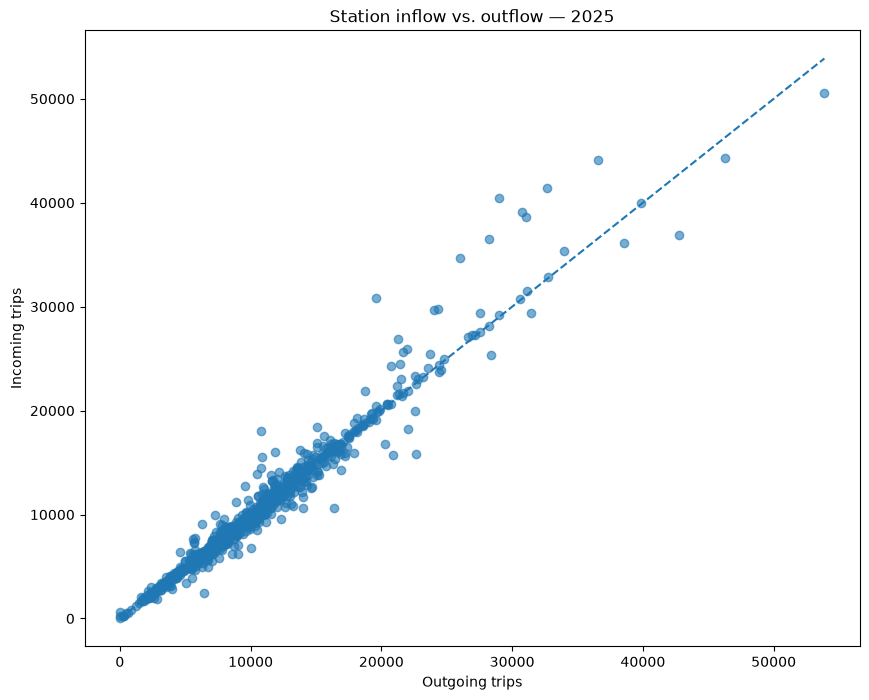

In [ ]:
#Inflow vs outflow graph
plot_df = station_analysis.to_pandas()

plt.figure(figsize=(10, 8))

plt.scatter(
    plot_df["weighted_out_degree"],
    plot_df["weighted_in_degree"],
    alpha=0.6
)

max_flow = max(
    plot_df["weighted_out_degree"].max(),
    plot_df["weighted_in_degree"].max()
)

plt.plot(
    [0, max_flow],
    [0, max_flow],
    linestyle="--"
)

plt.xlabel("Outgoing trips")
plt.ylabel("Incoming trips")
plt.title("Station inflow vs. outflow — 2025")

plt.show()

# Most points hug the dashed y=x line, i.e. for most stations inflow and
# outflow are roughly balanced over the year -- makes sense for a
# bike-share network where nearly every bike taken from a station
# eventually gets returned to the system. The points that sit furthest
# from the line are exactly the "largest imbalance" stations already
# surfaced before (e.g. 1067, 982, 2692) -- this plot is a useful
# visual cross-check that those aren't outliers of the ranking method,
# they're visibly off the diagonal.

****Weighted, directed community detection using Leiden****

In [28]:

# ============================================================
# Weighted, directed community detection using Leiden
# Replacement for graph-tool SBM
# ============================================================

import igraph as ig
import leidenalg as la
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Convert the NetworkX graph to an igraph graph
# ------------------------------------------------------------

# Preserve the original station IDs and their order.
stations = list(G.nodes())
station_to_vertex = {
    station: i for i, station in enumerate(stations)
}

# Create a directed graph with one vertex per station.
ig_graph = ig.Graph(
    n=len(stations),
    directed=True
)

# Store station IDs as vertex attributes.
ig_graph.vs["station"] = stations

# Convert NetworkX edges into igraph's integer vertex indices.
edge_list = [
    (station_to_vertex[source], station_to_vertex[target])
    for source, target in G.edges()
]

# Add all directed edges.
ig_graph.add_edges(edge_list)

# Copy trip counts to the corresponding igraph edges.
edge_weights = [
    float(G[source][target]["weight"])
    for source, target in G.edges()
]

ig_graph.es["weight"] = edge_weights

# Leiden requires positive edge weights for the selected
# configuration-based objective. Check the data before fitting.
if any(not np.isfinite(w) or w <= 0 for w in edge_weights):
    raise ValueError(
        "All edge weights must be finite and strictly positive."
    )

In [29]:

# ------------------------------------------------------------
# 2. Fit Leiden community detection
# ------------------------------------------------------------

# Resolution controls the granularity of the partition.
# Lower values often produce fewer, larger communities;
# higher values often produce more, smaller communities.
resolution = 1.0

# Fix the seed so the initial run is reproducible.
seed = 42

# Use the directed configuration-model objective.
partition = la.find_partition(
    ig_graph,
    la.RBConfigurationVertexPartition,
    weights="weight",
    resolution_parameter=resolution,
    n_iterations=-1,
    seed=seed
)

# Extract the community assigned to every station.
# Community IDs are relabelled from 0 for convenience.
membership = partition.membership

station_blocks = {
    station: int(membership[i])
    for i, station in enumerate(stations)
}

# Build the same Polars table used by the original workflow.
clusters_df = pl.DataFrame({
    "station": stations,
    "block": [station_blocks[s] for s in stations]
})


In [30]:

# ------------------------------------------------------------
# 3. Report the number and sizes of communities
# ------------------------------------------------------------

n_blocks = len(set(membership))

print("Number of communities:", n_blocks)
print("Leiden quality score:", partition.quality())

print(clusters_df)

# Count stations in each community and calculate percentages.
class_sizes = (
    clusters_df
    .group_by("block")
    .agg(pl.len().alias("n_stations"))
    .sort("n_stations", descending=True)
    .with_columns(
        (
            pl.col("n_stations")
            / pl.col("n_stations").sum()
            * 100
        ).alias("percentage")
    )
)

print(class_sizes)

Number of communities: 5
Leiden quality score: 3241173.1232529385
shape: (822, 2)
┌────────────┬───────┐
│ station    ┆ block │
│ ---        ┆ ---   │
│ i64        ┆ i64   │
╞════════════╪═══════╡
│ 959        ┆ 3     │
│ 960        ┆ 3     │
│ 961        ┆ 3     │
│ 962        ┆ 3     │
│ 963        ┆ 3     │
│ …          ┆ …     │
│ 200191444  ┆ 4     │
│ 200230444  ┆ 1     │
│ 300032444  ┆ 0     │
│ 300241444  ┆ 2     │
│ 2001454444 ┆ 2     │
└────────────┴───────┘
shape: (5, 3)
┌───────┬────────────┬────────────┐
│ block ┆ n_stations ┆ percentage │
│ ---   ┆ ---        ┆ ---        │
│ i64   ┆ u32        ┆ f64        │
╞═══════╪════════════╪════════════╡
│ 0     ┆ 214        ┆ 26.034063  │
│ 1     ┆ 204        ┆ 24.817518  │
│ 2     ┆ 158        ┆ 19.221411  │
│ 3     ┆ 130        ┆ 15.815085  │
│ 4     ┆ 116        ┆ 14.111922  │
└───────┴────────────┴────────────┘


In [31]:
# ------------------------------------------------------------
# 4. Summarise station statistics by community
# ------------------------------------------------------------

# Add community assignments to the existing station statistics.
station_analysis_clustered = station_analysis.join(
    clusters_df,
    on="station",
    how="left"
)

# Calculate average network characteristics per community.
block_summary = (
    station_analysis_clustered
    .group_by("block")
    .agg([
        pl.len().alias("n_stations"),
        pl.col("in_degree").mean().alias("mean_in_degree"),
        pl.col("out_degree").mean().alias("mean_out_degree"),
        pl.col("weighted_in_degree").mean().alias("mean_inflow"),
        pl.col("weighted_out_degree").mean().alias("mean_outflow"),
        pl.col("flow_imbalance").mean().alias("mean_imbalance"),
        pl.col("normalized_imbalance")
          .mean().alias("mean_normalized_imbalance"),
        pl.col("degree_centrality")
          .mean().alias("mean_degree_centrality"),
        pl.col("betweenness_centrality")
          .mean().alias("mean_betweenness"),
    ])
    .sort("block")
)

print(block_summary)

shape: (5, 10)
┌───────┬────────────┬────────────┬────────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ block ┆ n_stations ┆ mean_in_de ┆ mean_out_d ┆ … ┆ mean_imba ┆ mean_norm ┆ mean_degr ┆ mean_betw │
│ ---   ┆ ---        ┆ gree       ┆ egree      ┆   ┆ lance     ┆ alized_im ┆ ee_centra ┆ eenness   │
│ i64   ┆ u32        ┆ ---        ┆ ---        ┆   ┆ ---       ┆ balance   ┆ lity      ┆ ---       │
│       ┆            ┆ f64        ┆ f64        ┆   ┆ f64       ┆ ---       ┆ ---       ┆ f64       │
│       ┆            ┆            ┆            ┆   ┆           ┆ f64       ┆ f64       ┆           │
╞═══════╪════════════╪════════════╪════════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 0     ┆ 214        ┆ 536.018692 ┆ 537.313084 ┆ … ┆ -114.4065 ┆ -0.008553 ┆ 1.307347  ┆ 0.003583  │
│       ┆            ┆            ┆            ┆   ┆ 42        ┆           ┆           ┆           │
│ 1     ┆ 204        ┆ 502.568627 ┆ 499.946078 ┆ … ┆ -159.6911 ┆ -0.011166 ┆

In [32]:

# ------------------------------------------------------------
# 5. Calculate trips between communities
# ------------------------------------------------------------

# Map each edge's origin and destination to their communities.
edges_with_blocks = edges.with_columns(
    pl.col("source")
      .replace_strict(station_blocks, default=None)
      .alias("source_block"),

    pl.col("target")
      .replace_strict(station_blocks, default=None)
      .alias("target_block")
)

# Sum the trip counts for each origin-destination community pair.
block_flows = (
    edges_with_blocks
    .group_by(["source_block", "target_block"])
    .agg(pl.col("weight").sum().alias("total_trips"))
    .sort("total_trips", descending=True)
)

print(block_flows)

shape: (25, 3)
┌──────────────┬──────────────┬─────────────┐
│ source_block ┆ target_block ┆ total_trips │
│ ---          ┆ ---          ┆ ---         │
│ i64          ┆ i64          ┆ u32         │
╞══════════════╪══════════════╪═════════════╡
│ 1            ┆ 1            ┆ 1437099     │
│ 0            ┆ 0            ┆ 1431123     │
│ 2            ┆ 2            ┆ 873858      │
│ 3            ┆ 3            ┆ 778524      │
│ 4            ┆ 4            ┆ 544632      │
│ …            ┆ …            ┆ …           │
│ 4            ┆ 2            ┆ 107212      │
│ 1            ┆ 4            ┆ 54942       │
│ 4            ┆ 1            ┆ 54240       │
│ 1            ┆ 0            ┆ 48608       │
│ 0            ┆ 1            ┆ 45390       │
└──────────────┴──────────────┴─────────────┘


shape: (5, 6)
┌──────────────┬─────────┬─────────┬────────┬────────┬────────┐
│ source_block ┆ 1       ┆ 0       ┆ 2      ┆ 3      ┆ 4      │
│ ---          ┆ ---     ┆ ---     ┆ ---    ┆ ---    ┆ ---    │
│ i64          ┆ u32     ┆ u32     ┆ u32    ┆ u32    ┆ u32    │
╞══════════════╪═════════╪═════════╪════════╪════════╪════════╡
│ 0            ┆ 45390   ┆ 1431123 ┆ 269742 ┆ 124040 ┆ 256685 │
│ 1            ┆ 1437099 ┆ 48608   ┆ 239077 ┆ 345895 ┆ 54942  │
│ 2            ┆ 234698  ┆ 263243  ┆ 873858 ┆ 245153 ┆ 116112 │
│ 3            ┆ 321617  ┆ 111123  ┆ 233570 ┆ 778524 ┆ 185503 │
│ 4            ┆ 54240   ┆ 248400  ┆ 107212 ┆ 191869 ┆ 544632 │
└──────────────┴─────────┴─────────┴────────┴────────┴────────┘


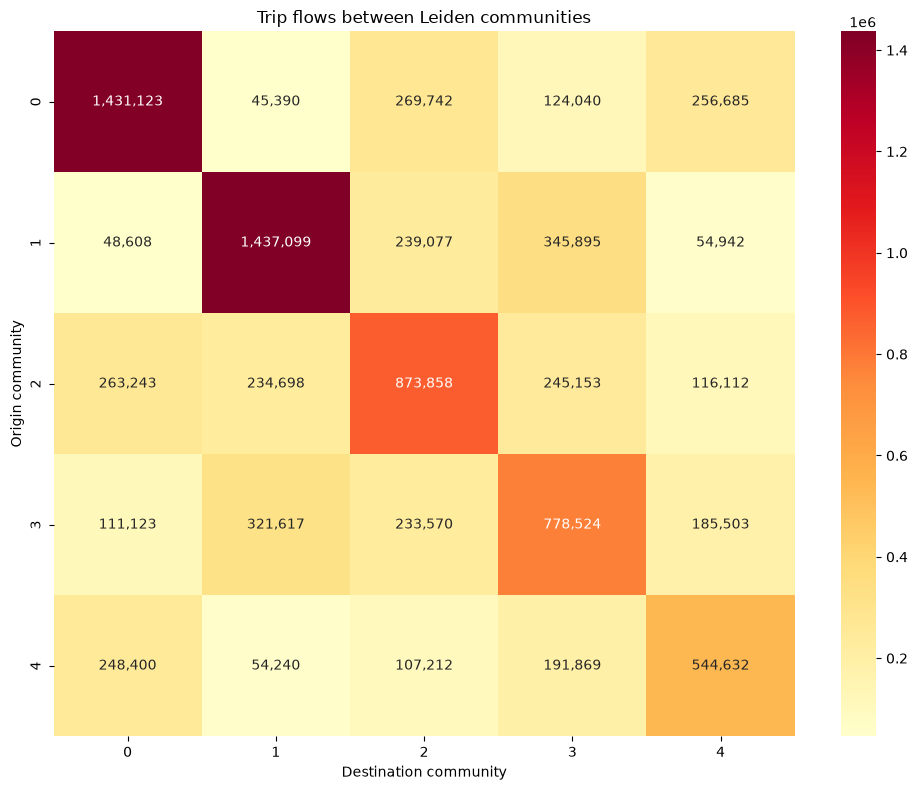

In [33]:

# ------------------------------------------------------------
# 6. Construct and plot the community flow matrix
# ------------------------------------------------------------

# Rows represent origin communities; columns represent
# destination communities.
flow_matrix = (
    block_flows
    .pivot(
        on="target_block",
        index="source_block",
        values="total_trips"
    )
    .fill_null(0)
    .sort("source_block")
)

print(flow_matrix)

# Convert to pandas for seaborn plotting.
flow_pd = flow_matrix.to_pandas().set_index("source_block")

# Sort destination columns numerically where possible.
flow_pd = flow_pd.reindex(
    sorted(flow_pd.columns, key=lambda x: int(x)),
    axis=1
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    flow_pd,
    annot=True,
    fmt=",.0f",
    cmap="YlOrRd"
)

plt.xlabel("Destination community")
plt.ylabel("Origin community")
plt.title("Trip flows between Leiden communities")
plt.tight_layout()
plt.show()


In [34]:

# ------------------------------------------------------------
# 7. Repeat clustering with different random seeds
# ------------------------------------------------------------

# Compare the number of communities and quality score across runs.
results = []

for run_seed in range(10):

    partition_i = la.find_partition(
        ig_graph,
        la.RBConfigurationVertexPartition,
        weights="weight",
        resolution_parameter=resolution,
        n_iterations=-1,
        seed=run_seed
    )

    results.append({
        "run": run_seed,
        "n_blocks": len(set(partition_i.membership)),
        "quality": partition_i.quality()
    })

results_df = pl.DataFrame(results)

print(results_df)

# Higher quality is better for the chosen objective.
print(
    results_df
    .sort("quality", descending=True)
)


shape: (10, 3)
┌─────┬──────────┬──────────┐
│ run ┆ n_blocks ┆ quality  │
│ --- ┆ ---      ┆ ---      │
│ i64 ┆ i64      ┆ f64      │
╞═════╪══════════╪══════════╡
│ 0   ┆ 5        ┆ 3.2292e6 │
│ 1   ┆ 5        ┆ 3.2395e6 │
│ 2   ┆ 4        ┆ 3.1875e6 │
│ 3   ┆ 5        ┆ 3.2191e6 │
│ 4   ┆ 5        ┆ 3.2408e6 │
│ 5   ┆ 5        ┆ 3.2195e6 │
│ 6   ┆ 4        ┆ 3.2637e6 │
│ 7   ┆ 5        ┆ 3.2065e6 │
│ 8   ┆ 4        ┆ 3.2614e6 │
│ 9   ┆ 4        ┆ 3.2117e6 │
└─────┴──────────┴──────────┘
shape: (10, 3)
┌─────┬──────────┬──────────┐
│ run ┆ n_blocks ┆ quality  │
│ --- ┆ ---      ┆ ---      │
│ i64 ┆ i64      ┆ f64      │
╞═════╪══════════╪══════════╡
│ 6   ┆ 4        ┆ 3.2637e6 │
│ 8   ┆ 4        ┆ 3.2614e6 │
│ 4   ┆ 5        ┆ 3.2408e6 │
│ 1   ┆ 5        ┆ 3.2395e6 │
│ 0   ┆ 5        ┆ 3.2292e6 │
│ 5   ┆ 5        ┆ 3.2195e6 │
│ 3   ┆ 5        ┆ 3.2191e6 │
│ 9   ┆ 4        ┆ 3.2117e6 │
│ 7   ┆ 5        ┆ 3.2065e6 │
│ 2   ┆ 4        ┆ 3.1875e6 │
└─────┴──────────┴──────────┘


****Comparison between models****

It is seen that both models behave similar and give similar results in terms of cluster amount. After doing the dimension reduction and creating the clusters via vectorial clustering we identified that either 2 or 4 clusters was the best number of clusters to choose and the variables that had most of the impact in the clusters were the number of trips from that station and towards that station. The results obtained from the SBM (or Leiden in this case) is having 5 instead of 4 clusters.

A difference is the amount of stations per cluster. In the vectorial clustering we see a 8% or 40% of data per cluster, its a huge difference between clusters. While in the Leiden clustering we have a 14% to 26% of data per cluster (much more balanced distribution). It looks like the clusters made by Leiden method are more homogeneous between each other vs the groups made in the vectorial clustering which look more different from each other

***SBM (graph-tool library needed)***

In [ ]:
####################
#Stochastic block model with toolgraph
####################

#------------
#Translate to graph-tool
#------------

gt_graph = gt.Graph(directed=True)

# Mapping NetworkX station IDs -> graph-tool vertex IDs
station_to_vertex = {}

for station in G.nodes():
    v = gt_graph.add_vertex()
    station_to_vertex[station] = int(v)

#Add edges
weight_prop = gt_graph.new_edge_property("double")

for source, target, data in G.edges(data=True):

    e = gt_graph.add_edge(
        station_to_vertex[source],
        station_to_vertex[target]
    )

    weight_prop[e] = data["weight"]

gt_graph.edge_properties["weight"] = weight_prop



NameError: name 'gt' is not defined

In [ ]:
#Poisson model with graph tool

state_poisson = gt.minimize_blockmodel_dl(
    gt_graph,
    state_args={
        "recs": [gt_graph.ep.weight],
        "rec_types": ["discrete-poisson"],
        "deg_corr": True,
    }
)


In [ ]:
#Inferred number of blocks
print("Number of blocks:", state_poisson.get_nonempty_B())

print("Model entropy:", state_poisson.entropy())


# 802 non-empty
# blocks out of 822 stations: i.e. almost every station ends up in its
# own block, with only a handful of stations sharing a block with
# anyone else
# this means this particular SBM configuration (directed, degree-corrected,
# weighted with a discrete-Poisson edge distribution) is not finding a
# small number of interpretable station "communities" -- it's telling
# you the trip pattern between any two stations is distinctive enough
# that DL-minimization prefers to keep them mostly separate

In [ ]:

#get class assigned to every station
blocks = state_poisson.get_blocks()
station_blocks = {}

for station, vertex_id in station_to_vertex.items():
    station_blocks[station] = int(
        blocks[gt_graph.vertex(vertex_id)]
    )

clusters_df = pl.DataFrame({
    "station": list(station_blocks.keys()),
    "block": list(station_blocks.values())
})

print(clusters_df)

In [ ]:
#Check size of each class
class_sizes = (
    clusters_df
    .group_by("block")
    .agg(
        pl.len().alias("n_stations")
    )
    .sort("n_stations", descending=True)
)

class_sizes = class_sizes.with_columns(
    (
        pl.col("n_stations")
        / pl.col("n_stations").sum()
        * 100
    ).alias("percentage")
)

print(class_sizes)

#802 rows (matching `state_poisson`'s
# block count), and the biggest block has only 3 stations (0.36%)
# Almost every block here is a singleton or pair: this is the concrete
# confirmation that the SBM, as configured, is assigning nearly every
# station its own class rather than finding a handful of meaningful
# station communities.



In [ ]:
#SMB with station stats for summary
station_analysis = station_analysis.join(
    clusters_df,
    on="station",
    how="left"
)

block_summary = (
    station_analysis
    .group_by("block")
    .agg([
        pl.len().alias("n_stations"),

        pl.col("in_degree")
        .mean()
        .alias("mean_in_degree"),

        pl.col("out_degree")
        .mean()
        .alias("mean_out_degree"),

        pl.col("weighted_in_degree")
        .mean()
        .alias("mean_inflow"),

        pl.col("weighted_out_degree")
        .mean()
        .alias("mean_outflow"),

        pl.col("flow_imbalance")
        .mean()
        .alias("mean_imbalance"),

        pl.col("normalized_imbalance")
        .mean()
        .alias("mean_normalized_imbalance"),

        pl.col("degree_centrality")
        .mean()
        .alias("mean_degree_centrality"),

        pl.col("betweenness_centrality")
        .mean()
        .alias("mean_betweenness"),
    ])
    .sort("block")
)

print(block_summary)



In [ ]:
#Flow between classes from SBM
edges_with_blocks = edges.with_columns(
    pl.col("source")
    .replace(station_blocks)
    .cast(pl.Int64)
    .alias("source_block"),

    pl.col("target")
    .replace(station_blocks)
    .cast(pl.Int64)
    .alias("target_block")
)

#Add trips
block_flows = (
    edges_with_blocks
    .group_by([
        "source_block",
        "target_block"
    ])
    .agg(
        pl.col("weight").sum().alias("total_trips")
    )
    .sort("total_trips", descending=True)
)

print(block_flows)



In [ ]:
#Block to block flow matrix
flow_matrix = (
    block_flows
    .pivot(
        on="target_block",
        index="source_block",
        values="total_trips"
    )
    .fill_null(0)
)

print(flow_matrix)

#since the matrix is 803x803, it is rather unreadable

In [ ]:
#plot flow matrix
flow_pd = flow_matrix.to_pandas().set_index("source_block")

plt.figure(figsize=(10, 8))

sns.heatmap(
    flow_pd,
    annot=True,
    fmt=",.0f"
)

plt.xlabel("Destination block")
plt.ylabel("Origin block")
plt.title("Trip flows between SBM blocks")

plt.show()


#since the matrix is 803x803, it is rather unreadable

In [ ]:
#Run model several times
results = []

for seed in range(10):

    np.random.seed(seed)

    state_i = gt.minimize_blockmodel_dl(
        gt_graph,
        state_args={
            "recs": [gt_graph.ep.weight],
            "rec_types": ["discrete-poisson"],
            "deg_corr": True,
        }
    )

    results.append({
        "run": seed,
        "n_blocks": state_i.get_nonempty_B(),
        "entropy": state_i.entropy(),
    })

print(pl.DataFrame(results))

# Across 10 different random seeds, minimize_blockmodel_dl consistently
# finds 801-819 blocks,
# tightly clustered around the 802 blocks reported for `state_poisson`
# earlier. This confirms two things: (1) the model's real, reproducible
# answer is "~800+ blocks" and
# (2) this isn't an unlucky single run -- the SBM genuinely and stably
# prefers near-one block per station for this graph/configuration, so
# getting a small number of interpretable groups out of this data would
# require changing the model setup 